# Rust or Python: how much faster is the code an AI model writes?

## A summary that runs every morning

A web server writes one line to its access log for every request it answers: when the request arrived, which
page was asked for, whether it worked and how long the server took. A busy site writes a couple of million such
lines a day. Every morning someone wants a short summary: how many requests failed, which pages were the
busiest, and how slow the slowest answers were for each of those pages.

A short Python program can produce that summary. It reads the file one line at a time, checks that each line has
the expected shape, pulls out the page and the time taken, and keeps running counts. For the 2-million-line log
used in this notebook, a straightforward version takes about 5 seconds on a recent laptop.

Five seconds is nothing for a job that runs once a day. It matters when the same work runs thousands of times: on
every file in a data pipeline, behind a dashboard that someone is waiting on, or on a cloud machine billed by the
second. Memory matters in the same way. A program that keeps every page's response times needs room for them,
and whether a job fits in the memory of a small machine decides whether it runs at all.

## Why the same steps can take very different times

Python is interpreted. A program called the interpreter reads your code and carries out each operation as it
comes to it. Before it adds two numbers it checks what kind of values they are, finds the right way to add that
kind, and creates a new object to hold the result. That flexibility is what makes Python quick to write: a
variable can hold anything, and nothing needs declaring. It also means that a loop over two million log lines
repeats that bookkeeping two million times.

Rust is compiled. Before the program runs, a compiler translates it into the processor's own instructions, and it
knows in advance that a count is a 64-bit integer and a latency is another. The loop that adds up response times
becomes a few machine instructions per line, with no type checks and no new objects. The compiler is strict in
return: a program does not build until every type and every use of memory is accounted for, and building takes
time.

Take an illustrative case, adding up a million whole numbers. A Python `for` loop looks up the meaning of `+` for
each pair of values and allocates a new number each time. A Rust loop keeps the running total in a register of
the processor. Nobody needs an experiment to predict that Rust wins this one. The useful question is by how much
on realistic work, where reading files, splitting text and looking things up in tables also take time.

## Python's usual shortcut

Experienced Python programmers rarely write that loop. They use NumPy, a library written in C that stores a
million numbers in one compact block of memory and adds them up in one call, `values.sum()`. The loop still runs,
but in compiled code. A program written this way is still Python, yet for arithmetic on arrays it can run close
to compiled speed.

The catch is that NumPy only helps when the work can be written as the same operation applied to a whole array at
once. One task here fits that shape well: spreading heat across a floor plan, where every cell of a grid is
updated by the same formula at each step. Many everyday tasks do not. Reading a line of JSON, deciding whether a
log line is well formed, or finding the shortest route through a road network one junction at a time all involve
a decision for each item, and whole-array operations express decisions badly.

So "how much faster is Rust than Python" has at least three sides: plain Python, Python that leans on NumPy, and
Rust. The answer can differ from one task to the next.

## What changes when a model writes the code

The usual argument for Python is that it is cheaper to write. Rust code is longer, its compiler rejects more first
drafts, and a developer has to know the language well to make it fast. Teams often accept slower Python because
the faster version would cost too much developer time.

AI coding models change part of that calculation. Asking a model for a Rust version costs about the same as asking
for a Python version. If the model's Rust is correct and fast, a team gets the speed without paying much for it. If
the model writes Rust that is wrong, or no faster than its Python, the gain is not there. Published language
benchmarks, built from programs that experts tuned by hand, cannot answer this. The code that matters here is the
code a model writes when it is asked.

## The question

When an AI coding model writes the same program three ways (Rust, Python with only the standard library, and Python
with NumPy), how much faster and how much smaller in memory is the Rust version, how much of the gap does NumPy
close, and does each version still give the right answer?

The comparison uses eight tasks written for this study on 2026-10-30, so no model could have seen them or their
answers before. Two models wrote all three versions of every task: Claude Sonnet 5.5 and GPT-6.1 Terra, 48 programs
in all. A straightforward standard-library solution of each task, written for clarity rather than speed, is timed
as a fourth version called "simple Python". It shows what an ordinary Python program would take.

## Study summary

**What was compared.** Each model worked on each task in its own folder for a few minutes to half an hour, with the
Rust and Python toolchains, a precise specification and small sample inputs with their expected outputs. Its
programs were then run on hidden inputs, including one benchmark-sized input per task (2 million log lines, a
million JSON transactions, a 300,000-node road network, and so on), and timed five times each on the same laptop.

**Correctness.** All 48 programs gave the exact expected output on every hidden input, as did the eight
simple-Python solutions. Correctness sits at its ceiling, so it cannot separate the languages or the models.

**Speed.** The measure is the speed-up: a Python version's run time divided by the Rust version's run time on the
same task, so 6x means Rust finished in one sixth of the time. Rust was the fastest version in all 16
task-and-model pairs. Against the faster of each model's two Python versions, Rust was **6.0 times faster** on
average (geometric mean over 16 pairs; 6.4x for Sonnet, 95% interval 4.4 to 9.1, and 5.6x for Terra, 3.8 to 8.3),
ranging from 2.2x to 14.5x. Against plain standard-library Python the gap was about 25x, and against simple Python
about 41x.

**NumPy.** NumPy closed most of the gap on numeric tasks, where it made Python 3 to 28 times faster than the same
model's plain version. It gave nothing on parsing JSON or log lines, and on two of those tasks the NumPy version was
slower than the plain one.

**In the original situation.** The morning log summary took 3.1 to 3.9 seconds in the models' Python and 0.46 to
1.2 seconds in their Rust. A daily job would not notice; a pipeline running it on thousands of files would cut its
compute time by roughly three to seven times.

**Main caveat.** Each model wrote each program once, on one Windows laptop that was running other work during the
timing (a median of 8 of its 22 logical processors were busy elsewhere). The large ratios are well beyond that
noise; differences under about 30% between two programs, or between the two models, are not.

## Contents

1. [Setup and saved data](#1-setup-and-saved-data)
2. [The machine](#2-the-machine)
3. [The models](#3-the-models)
4. [The eight tasks](#4-the-eight-tasks)
5. [How the models wrote the programs](#5-how-the-models-wrote-the-programs)
6. [How the programs were checked and timed](#6-how-the-programs-were-checked-and-timed)
7. [Worked example: the heat task from spec to speed-up](#7-worked-example-the-heat-task-from-spec-to-speed-up)
8. [Correctness](#8-correctness)
9. [Run time on the full inputs](#9-run-time-on-the-full-inputs)
10. [How much faster Rust was](#10-how-much-faster-rust-was)
11. [Where NumPy helps](#11-where-numpy-helps)
12. [Memory](#12-memory)
13. [Small inputs and start-up time](#13-small-inputs-and-start-up-time)
14. [More cores](#14-more-cores)
15. [Code size and build time](#15-code-size-and-build-time)
16. [The two models, and two larger models on heat](#16-the-two-models-and-two-larger-models-on-heat)
17. [Error analysis: slow choices, not wrong answers](#17-error-analysis-slow-choices-not-wrong-answers)
18. [Measurement quality](#18-measurement-quality)
19. [Limitations](#19-limitations)
20. [What the evidence supports](#20-what-the-evidence-supports)
21. [How the study got here](#21-how-the-study-got-here)
22. [How to reproduce](#22-how-to-reproduce)
23. [Spend](#23-spend)
24. [Future work and further reading](#24-future-work-and-further-reading)

### How the experiment runs

```mermaid
flowchart LR
    spec["8 task specs<br/>+ 3-5 small samples each"] --> sess["16 agent sessions<br/>2 models x 8 tasks"]
    sess --> progs["48 programs<br/>Rust, plain Python, NumPy Python"]
    gen["Input generators<br/>fixed seeds"] --> hidden["Hidden inputs per task<br/>t1 (small) + full (benchmark)"]
    ref["Simple-Python reference<br/>+ independent 2nd implementation"] --> exp["Expected outputs<br/>55 inputs, all agreeing"]
    progs --> build["16 Rust builds<br/>3 clean + 1 incremental each"]
    build --> check["Correctness<br/>every program on samples, t1, full"]
    progs --> check
    hidden --> check
    exp --> check
    check --> time["Timing: 1 warm-up + 5 runs<br/>56 programs on full inputs"]
    time --> out["Run time, peak memory,<br/>size sweep, 1-16 workers"]
```

One task travels through this as follows. The heat task's spec and samples go into a fresh folder for each model.
The model writes `rust/src/main.rs`, `plain.py` and `fast.py`, compiles and tests them on the samples, and stops.
The harness copies the three files out, builds the Rust program, and runs all three programs on a hidden small
input (`t1`) and on the hidden benchmark grid (`full`). Each output is compared with the expected output, which
was computed by the simple-Python reference and confirmed by a second, independently written implementation.
Programs that pass are timed five times on the benchmark input, taking turns with the other programs for the same
task, and the median time is the program's score. Section 7 follows heat through every step.

The test scripts that ran the sessions and took the measurements live in `bench/`. This notebook only reads their
saved results in `data/`, so running it makes no model calls and no timing runs.

## 1. Setup and saved data

The setup cell loads every saved result table and keeps only rows that match the current programs and inputs: each
row carries the SHA-256 hash of the program file and of the input it ran on, and a row whose hashes no longer match
is ignored. It also fixes the four version names and their colours used in every figure: grey for simple Python,
blue for plain Python, orange for NumPy Python and green for Rust. Filled markers are Claude Sonnet 5.5 and open
markers GPT-6.1 Terra.

Two flags at the top, `RUN_SESSIONS` and `RUN_MEASUREMENTS`, are off. Turning them on would rerun the model
sessions (cached by request hash, so nothing is spent while the saved programs match) and the measurements, which
take about an hour and replace the saved timings.

In [1]:
from pathlib import Path
import hashlib, json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

RUN_SESSIONS = False
RUN_MEASUREMENTS = False
if RUN_SESSIONS:
    subprocess.run([sys.executable, '-m', 'bench.sessions', 'run-all'], check=True)
if RUN_MEASUREMENTS:
    subprocess.run([sys.executable, '-m', 'bench.measure', 'all'], check=True)
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 12, 'figure.dpi': 150, 'savefig.dpi': 150, 'axes.grid': True, 'grid.alpha': .22})
DATA = Path('data'); RESULTS = DATA / 'results'; FIGURES = Path('figures'); DERIVED = RESULTS / 'derived'
FIGURES.mkdir(exist_ok=True); DERIVED.mkdir(exist_ok=True)
TASKS = ['springs', 'wordpairs', 'ledger', 'logscan', 'routes', 'align', 'heat', 'walkers']
AUTHORS = ['sonnet', 'terra']; VERSIONS = ['simple', 'plain', 'fast', 'rust']
LABELS = dict(simple='Simple Python', plain='Plain Python', fast='NumPy Python', rust='Rust')
COLORS = dict(simple='#777777', plain='#0072B2', fast='#D55E00', rust='#009E73')
MARKERS = dict(simple='o', plain='s', fast='^', rust='D')
manifest = json.loads((DATA / 'inputs_manifest.json').read_text(encoding='utf-8'))['inputs']
entries = {(x['task'], x['name']): x for x in manifest}
machine = json.loads((DATA / 'machine.json').read_text(encoding='utf-8'))
def source_hash(author, task, variant):
    folder = DATA / 'programs' / author / task
    if variant == 'rust':
        folder = folder / 'rust'; h = hashlib.sha256()
        if not (folder / 'src/main.rs').is_file() or not (folder / 'Cargo.toml').is_file(): return None
        for p in sorted(folder.rglob('*')):
            if p.is_file() and p.suffix in ('.py', '.rs', '.toml') and 'target' not in p.parts:
                h.update(p.relative_to(folder).as_posix().encode()); h.update(hashlib.sha256(p.read_bytes()).digest())
        return h.hexdigest()
    p = folder / (variant + '.py')
    return hashlib.sha256(p.read_bytes()).hexdigest() if p.is_file() else None
exclusions = []
def current_rows(df, name):
    keep = []
    for _, r in df.iterrows():
        author, task = r['author'], r['task']
        variant = r.get('variant', 'rust')
        expected_source = source_hash(author, task, variant)
        reasons = []
        if expected_source is None: reasons.append('program missing')
        elif 'source_sha256' in df and r['source_sha256'] != expected_source: reasons.append('source hash mismatch')
        elif 'source_sha256' not in df:
            # LOC records have no hash; require a current correctness record for the same source.
            if (author, task, variant, expected_source) not in verified_sources: reasons.append('source not verifiable from correctness')
        if 'input_sha256' in df:
            entry = entries.get((task, r['input']))
            if entry is None or r['input_sha256'] != entry['sha256']: reasons.append('input hash mismatch')
        keep.append(not reasons)
        if reasons: exclusions.append(dict(table=name, author=author, task=task, variant=variant, input=r.get('input', ''), reason=', '.join(reasons)))
    out = df.loc[keep].copy()
    if 'variant' in out: out.loc[out.author.eq('reference') & out.variant.eq('plain'), 'variant'] = 'simple'
    return out
raw_correctness = pd.read_csv(RESULTS / 'correctness.csv')
verified_sources = set()
correctness = current_rows(raw_correctness, 'correctness')
verified_sources = {(r.author, r.task, 'plain' if r.variant == 'simple' else r.variant, r.source_sha256) for r in correctness.itertuples()}
tables = {name: current_rows(pd.read_csv(RESULTS / (name + '.csv')), name) for name in ['builds', 'loc', 'runs', 'sweep', 'scaling']}
baseline = pd.read_csv(RESULTS / 'baseline.csv')
runs, sweep, scaling, builds, loc = (tables[x] for x in ['runs', 'sweep', 'scaling', 'builds', 'loc'])
reference_times = pd.read_csv(DATA / 'reference_times.csv').drop_duplicates(['task', 'name'], keep='last')
def geom(values):
    x = np.asarray(values, dtype=float); x = x[np.isfinite(x) & (x > 0)]
    return np.exp(np.log(x).mean()) if len(x) else np.nan
def savefig(name):
    plt.savefig(FIGURES / name, bbox_inches='tight'); plt.show()
def legend_handles():
    return [Line2D([0], [0], marker=MARKERS[v], color=COLORS[v], linestyle='-', label=LABELS[v]) for v in VERSIONS]

## 2. The machine

All programs ran on one laptop, so its details are part of the result. The processor mixes six performance cores,
each running two threads, with slower efficiency cores. Single-threaded programs were held to the performance cores
so that the operating system could not move them to a slower core between runs. The table lists the processor, the
core counts, memory, Windows build, power plan and the language versions.

In [2]:
cores = machine['cpu_sets']; top = max(x['efficiency'] for x in cores)
pcores = len({(x['group'], x['core']) for x in cores if x['efficiency'] == top})
ecores = len({(x['group'], x['core']) for x in cores if x['efficiency'] != top})
display(pd.DataFrame({'value': {'CPU': machine['cpu_name'], 'P-cores': pcores, 'E-cores': ecores,
    'RAM (GB)': round(machine['ram_bytes']/1e9, 2), 'Windows': machine['windows'], 'Windows build': machine['windows_build'],
    'Power plan': machine['active_power_plan'], 'AC power': machine['on_ac_power'], 'Python': machine['python_version'],
    'NumPy': machine['numpy_version'], 'rustc': machine['rustc_version'], 'cargo': machine['cargo_version']}}))

,value
CPU,Intel(R) Core(TM) Ultra 9 185H
P-cores,6
E-cores,10
RAM (GB),33.74
Windows,Windows-11-10.0.26300-SP0
Windows build,26300
Power plan,Power Scheme GUID: 6fecc5ae-f350-48a5-b669-b47...
AC power,True
Python,"3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:..."
NumPy,2.2.6


## 3. The models

Two models wrote the 48 programs: Claude Sonnet 5.5, run through Anthropic's `claude -p` command, and GPT-6.1
Terra, run through OpenAI's `codex exec`, both at high reasoning effort. Two larger models, Claude Opus 5.5 and
GPT-6.1 Sol, wrote only the heat task, in the first test of the pipeline, kept as a side comparison in section 16.

The models do not have dated version names, so the pinned version is the model name the command-line tool
accepted on 2026-10-30, with the tool's version. Claude Code reports the model name in its session log; Codex does
not, so only the requested name is shown for the OpenAI models. No model's size or numeric precision is published.

In [3]:
sessions = pd.read_csv(DATA / 'sessions.csv')
pilots = [json.loads((DATA / 'programs' / a / 'heat' / 'meta.json').read_text(encoding='utf-8')) for a in ['opus', 'sol']]
sessions = pd.concat([sessions, pd.DataFrame(pilots)], ignore_index=True)
def usage(x): return json.loads(x) if isinstance(x, str) else (x if isinstance(x, dict) else {})
sessions['input_tokens'] = sessions.usage.map(lambda x: usage(x).get('input_tokens', 0))
sessions['output_tokens'] = sessions.usage.map(lambda x: usage(x).get('output_tokens', 0))
sessions['cache_read_tokens'] = sessions.usage.map(lambda x: usage(x).get('cache_read_input_tokens', usage(x).get('cached_input_tokens', 0)))
sessions['cache_creation_tokens'] = sessions.usage.map(lambda x: usage(x).get('cache_creation_input_tokens', 0))
why = {'sonnet': "Anthropic's coding model for all 16 main sessions; replaced Opus 5.5 to save subscription quota",
       'terra': "OpenAI's model for the same 16 sessions; replaced Sol for the same reason",
       'opus': 'Larger Anthropic model, heat pilot only', 'sol': 'Larger OpenAI model, heat pilot only'}
model_names = {'sonnet': 'Claude Sonnet 5.5', 'terra': 'GPT-6.1 Terra', 'opus': 'Claude Opus 5.5', 'sol': 'GPT-6.1 Sol'}
model_rows = []
for a in ['sonnet', 'terra', 'opus', 'sol']:
    s = sessions[sessions.author.eq(a)]
    model_rows.append({'model': model_names[a], 'pinned version (requested / reported)': ' / '.join(sorted(set(s.requested_model.dropna()))) + ' / ' + (', '.join(sorted(set(s.reported_model.dropna()))) or 'not reported'),
        'provider and call': 'Anthropic, claude -p' if a in ['sonnet', 'opus'] else 'OpenAI, codex exec',
        'CLI version': ', '.join(sorted(set(s.cli_version.dropna()))), 'size and precision': 'not published',
        'settings': 'effort high; Bash, Read, Write, Edit, Glob, Grep' if a in ['sonnet', 'opus'] else 'effort high; workspace tools', 'why included': why[a]})
display(pd.DataFrame(model_rows))

,model,pinned version (requested / reported),provider and call,CLI version,size and precision,settings,why included
0,Claude Sonnet 5.5,claude-sonnet-5-5 / claude-sonnet-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; Bash, Read, Write, Edit, Glob, Grep",Anthropic's coding model for all 16 main sessi...
1,GPT-6.1 Terra,gpt-6.1-terra / not reported,"OpenAI, codex exec",codex-cli 0.160.1,not published,effort high; workspace tools,OpenAI's model for the same 16 sessions; repla...
2,Claude Opus 5.5,claude-opus-5-5 / claude-opus-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; Bash, Read, Write, Edit, Glob, Grep","Larger Anthropic model, heat pilot only"
3,GPT-6.1 Sol,gpt-6.1-sol / not reported,"OpenAI, codex exec",codex-cli 0.160.1,not published,effort high; workspace tools,"Larger OpenAI model, heat pilot only"


Several other models took part in building the study, but none is measured: the task specs and this text were
written by Claude Opus 5.5, the input generators, simple-Python reference and measurement scripts by GPT-6.1 Sol,
this notebook's code by GPT-6.1 Terra, and figure changes by Claude Sonnet 5.5.

## 4. The eight tasks

The tasks cover the kinds of work people write scripts for, from pure arithmetic to text and record handling:

- **springs**: 4,000 masses joined by springs in a ring, moved for 15,000 time steps; report the energy. A
  floating-point loop.
- **wordpairs**: count how often each pair of adjacent words occurs in 10 million words of text; report the 20
  most common pairs. Text and hash tables.
- **ledger**: total a million JSON bank transactions per channel and account, with exact currency conversion.
  Parsing records.
- **logscan**: the morning log summary from the introduction, over 2 million lines. Parsing text with a pattern.
- **routes**: shortest road distances from 6 starting points in a 300,000-node network. Graph search.
- **align**: the cheapest weighted edit from one string to another, for 300 pairs. A dynamic-programming table.
- **heat**: heat spreading across a 400 x 400 floor plan for 250 steps, in exact integer arithmetic. Grid
  arithmetic.
- **walkers**: 64 random walks of 500,000 steps each, with a fixed random-number generator, spread over a given
  number of workers. Parallel simulation.

Each task has a written spec with exact input and output formats, in `bench/tasks/<task>/SPEC.md`. The inputs are
generated by code from fixed seeds, so they are new and the expected answers are exact. The table below gives the
benchmark input's size and generator settings, and the median time of the simple-Python solution on it. The second
table is how long the reference took when it first generated the expected outputs.

In [4]:
work = {'springs': 'particle simulation', 'wordpairs': 'text pair counting', 'ledger': 'transaction aggregation', 'logscan': 'log parsing and aggregation', 'routes': 'shortest paths', 'align': 'sequence alignment', 'heat': 'grid simulation', 'walkers': 'parallel random walks'}
ref = runs[(runs.author == 'reference') & (runs.input == 'full')].groupby('task').wall_seconds.median()
display(pd.DataFrame([{'task': t, 'work': work[t], 'full input bytes': entries[t, 'full']['bytes'], 'parameters': json.dumps(entries[t, 'full']['parameters']), 'simple Python median (s)': ref.get(t)} for t in TASKS]))
display(reference_times.rename(columns={'wall_seconds': 'reference generation time (s)'}))

,task,work,full input bytes,parameters,simple Python median (s)
0,springs,particle simulation,380975,"{""N"": 4000, ""P"": 4000, ""S"": 15000, ""dt"": 0.0005}",11.955443
1,wordpairs,text pair counting,65546152,"{""vocabulary"": 40000, ""words"": 10000000}",44.097943
2,ledger,transaction aggregation,381005817,"{""accounts"": 10000, ""channels"": 8, ""currencies...",7.889805
3,logscan,log parsing and aggregation,227676727,"{""lines"": 2000000, ""malformed_period"": 100, ""t...",4.967117
4,routes,shortest paths,14809532,"{""M"": 900000, ""N"": 300000, ""Q"": 6}",8.926864
5,align,sequence alignment,270579,"{""P"": 300, ""alphabet"": 10, ""max_length"": 1000,...",8.935762
6,heat,grid simulation,160412,"{""H"": 400, ""S"": 250, ""W"": 400}",13.038243
7,walkers,parallel random walks,35,"{""B"": 300, ""J"": 64, ""L"": 500000, ""SEED"": 18446...",15.476492


,task,name,reference generation time (s)
64,springs,s1a,0.315226
66,wordpairs,full,54.052765
67,ledger,full,11.368453
68,logscan,full,6.788517
69,routes,full,11.134631
70,align,full,20.151020
71,heat,full,20.907135
72,walkers,full,32.018223
73,logscan,s2,0.165326
74,springs,s1b,0.146755


### A look at the data

The input generators add the awkward cases a real file would contain. The log has truncated lines, lower-case
methods and latencies missing their decimal, about 1% of lines in all, which must be counted as malformed. The JSON
transactions contain decoy fields with the same names nested inside other objects, escaped quotes and emoji written
as escape codes, so a program that searches the text for `"account"` instead of parsing the JSON gets the wrong
total. The heat floor plans mark walls with `#`, heat sources with a digit and open floor with `.`. The cell below
prints the first lines of a small sample input and its expected output for these three tasks.

In [5]:
for task in ['logscan', 'ledger', 'heat']:
    print('\n', task)
    for suffix in ['in', 'out']:
        lines = (DATA / 'samples' / task / ('s2.' + suffix)).read_text(encoding='utf-8').splitlines()
        print('s2.' + suffix)
        for line in (lines[:6] if suffix == 'in' else lines): print(line[:140] + ('…' if len(line) > 140 else ''))


 logscan
s2.in
2026-10-30T14:22:05.123Z web-17 GET
2026-10-30T14:22:05.123Z web-17 GET /service/36a/v2/?ref=abc&item=12 200 1834B 9.5ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /service/53a/v2/71170 200 1834B 9.8ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /api/v2/items/6929 200 1834B 10.9ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /x//69521/12a 200 1834B 9.6ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /api/v2/items/80123?ref=abc&item=12 200 1834B 39.7ms "Mozilla/5.0 (X11; Linux x86_64)"
s2.out
lines 2000
malformed 40
status 1xx 16
status 2xx 1558
status 3xx 153
status 4xx 147
status 5xx 86
path /api/v2/items/{id} 227 13.4 170.0 697.9
path /users/{id}/orders/ 149 12.8 94.2 334.4
path /x//{id}/12a 91 13.9 162.8 250.9
path /{id}/{id}/{id} 62 15.3 73.5 306.1
path /health 61 8.2 82.8 203.7
path /service/0a/v2// 54 22.9 303.9 422.4
path /service/1a/v2/{id} 42 14.5 123.2 1014.3


The first logscan output line counts all 2,000 lines of the sample, the second the malformed ones (the first
sample line is a truncated request). A `path` line such as `path /api/v2/items/{id} 227 13.4 170.0 697.9` says the
page template `/api/v2/items/{id}` (any numeric item id) was requested 227 times, with a median latency of 13.4 ms,
a 95th percentile of 170.0 ms and a maximum of 697.9 ms. The ledger line shows a decoy `extra` object holding its
own `account`, `tags` and `type` fields, which a correct program ignores.

## 5. How the models wrote the programs

Each model ran as an agent: a loop in which it reads files, writes code, runs commands such as `cargo build` or
`python plain.py samples/s2.in`, reads the results and decides what to do next, until it judges the work finished.
There is one session per model and task, 16 in all, each in a fresh folder outside the repository.

```mermaid
flowchart TD
    p["Same prompt for every task<br/>+ SPEC.md + samples/ + Cargo project"] --> m["Model<br/>Sonnet 5.5 via claude -p, or Terra via codex exec<br/>effort high"]
    m -->|"writes code, runs a command"| t["Shell in the task folder<br/>cargo build --release --offline<br/>python plain.py samples/s2.in"]
    t -->|"output, errors, timings"| m
    m -->|"judges the work done"| out["rust/src/main.rs, plain.py, fast.py<br/>+ a short summary"]
```

The prompt was identical for every task and both models (`bench/AUTHOR_PROMPT.md`). Its key instructions:

> Every version must print the correct output for any valid input as SPEC.md defines it, not only for the
> samples. Make each version as fast as you can. Write each one the way a skilled developer in that language
> would write fast code, using that language's own strengths. Use a single thread and a single process unless
> SPEC.md says otherwise.

Rust programs could use four common libraries (serde and serde_json for JSON, regex for patterns, rayon for parallel
loops), downloaded in advance so the build works offline. The plain-Python version could use only the standard
library, and the NumPy version could add NumPy 2.2.

Asking for the fastest version matters for reading the results. The models' plain Python is Python written for
speed by a capable model, which is not the same as Python written by someone in a hurry. That is why the
simple-Python reference is timed as well.

The table shows each session's length, the number of turns and tool calls (each command, file read or edit is one
call), the tokens read and written, and the cost where the tool reports one.

In [6]:
sessions['minutes'] = sessions.wall_seconds / 60
session_cols = ['author', 'task', 'minutes', 'turns', 'tool_calls', 'input_tokens', 'output_tokens', 'cache_read_tokens', 'cache_creation_tokens', 'cost_usd']
display(sessions[session_cols].sort_values(['author', 'task']).round(2))
display(sessions.groupby('author')[session_cols[2:]].sum(min_count=1).round(2))

,author,task,minutes,turns,tool_calls,input_tokens,output_tokens,cache_read_tokens,cache_creation_tokens,cost_usd
16,opus,heat,8.03,31,30,56,29010,769677,47480,1.11
17,sol,heat,11.86,1,30,753520,22568,670720,0,NaN
0,sonnet,align,4.00,15,14,28,14384,261887,22578,0.26
1,sonnet,heat,3.55,19,18,34,16401,327490,22054,0.29
2,sonnet,ledger,11.56,43,42,78,34058,1386419,48100,0.67
3,sonnet,logscan,9.63,20,19,38,24288,493788,33846,0.43
4,sonnet,routes,15.41,37,36,70,23606,911398,35626,0.47
5,sonnet,springs,4.59,9,8,16,7600,98306,13196,0.14
6,sonnet,walkers,8.11,31,30,60,35504,1044918,45258,0.64
7,sonnet,wordpairs,23.56,62,61,116,67388,2777688,82808,1.28


,minutes,turns,tool_calls,input_tokens,output_tokens,cache_read_tokens,cache_creation_tokens,cost_usd
author,,,,,,,,
opus,8.03,31,30,56,29010,769677,47480,1.11
sol,11.86,1,30,753520,22568,670720,0,NaN
sonnet,80.40,236,228,440,223229,7301894,303466,4.18
terra,24.69,8,73,2224819,42685,1974272,0,NaN


Sonnet's sessions took 3.5 to 24 minutes (80 minutes in all, USD 4.18) and made 8 to 61 tool calls; its longest
was wordpairs. Terra's took 2 to 4 minutes (25 minutes in all) with 4 to 15 tool calls each. Both models tested all
three versions on every sample before finishing, and both wrote extra tests of their own, from random small inputs
checked against a brute-force solution to hand-made edge cases. Terra iterated less, which shows later in plainer
programs.

## 6. How the programs were checked and timed

**Correct answers.** For each task, a straightforward reference solution produced the expected output for every
input, and a second solution written a different way (for example a different shortest-path algorithm, or a
hand-written JSON reader) had to agree before the input was used. All 55 inputs agreed. A program's output is
compared field by field with the expected output. A failure would fall into one of several kinds: the program did
not build, crashed, ran out of time, wrote output that cannot be read in the required format, or wrote readable
output with a wrong value. Only the last kind is a wrong answer; the others are failures to deliver one. For the
spring simulation, which uses floating-point numbers, values within one part in a billion of the expected value
count as equal, because adding the same numbers in a different order can change the last digits.

**Timing.** Every correct program ran once to warm up the disk cache and then five more times on the benchmark
input, taking turns with the other programs for the same task in a shuffled order. The score is the median of the
five times: the wall-clock time from starting the program to its exit, as a user would wait for it. That includes
starting the interpreter or executable, reading the input and printing the answer.

**Memory.** Peak memory is the largest amount of physical memory the program held at once (Windows calls it the
peak working set). For the walkers task it is the total memory committed by all of the program's processes,
because the Python versions start one process per worker.

**Speed-up and its average.** The speed-up compares two versions of the same task: a Python time of 3.1 s and a
Rust time of 0.46 s give 3.1 / 0.46 = 6.8x. Averaging speed-ups across tasks uses the geometric mean (multiply the
ratios and take the matching root), because an ordinary average lets one large ratio dominate. For two tasks with
speed-ups of 2x and 50x, the ordinary average is 26x, which describes neither; the geometric mean is 10x, the ratio
that, applied to both tasks, gives the same product. The 95% intervals come from resampling the eight tasks with
replacement 10,000 times, so they show how much the average depends on which tasks were chosen.

## 7. Worked example: the heat task from spec to speed-up

The heat task describes a floor plan of 400 x 400 cells. Open cells start at 0, heat sources hold a fixed value, and
at each of 250 steps every open cell becomes `(4 * old + up + down + left + right) // 8`, where a neighbour that is
a wall, or lies outside the grid, contributes the cell's own old value. The answer is the sum of all open cells,
the hottest cell and its position, and a checksum. Integer arithmetic keeps the answer exact in every language.

Claude Sonnet 5.5 spent 3.5 minutes and 18 tool calls on heat. Its three programs take three different routes to
the same arithmetic. The next cell defines two helpers: `show_code` prints numbered lines of a saved program, and
`show_run` prints a program's correctness checks and timing summary. Then the Rust version's time-step loop:

In [7]:
def show_code(author, task, variant, start, end):
    variant = 'plain' if variant == 'simple' else variant
    path = DATA / 'programs' / author / task / ('rust/src/main.rs' if variant == 'rust' else variant + '.py')
    for i, line in enumerate(path.read_text(encoding='utf-8').splitlines(), 1):
        if start <= i <= end: print(f'{i:4}  {line}')
def show_run(author, task, variant, input):
    c = correctness[(correctness.author==author)&(correctness.task==task)&(correctness.variant==variant)&(correctness.input==input)]
    c = c[['workers','status','detail','stdout']].copy(); c['stdout'] = c.stdout.fillna('').astype(str).str[:200]; display(c)
    t = pd.concat([runs,sweep,scaling],ignore_index=True)
    t = t[(t.author==author)&(t.task==task)&(t.variant==variant)&(t.input==input)]
    display(t.groupby('workers').wall_seconds.agg(['count','median','min','max']))

In [8]:
show_code('sonnet', 'heat', 'rust', 49, 66)

  49      for _ in 0..steps {
  50          for r in 1..=h {
  51              let base = r * wp + 1;
  52              let o = &cur[base..base + w];
  53              let up = &cur[base - wp..base - wp + w];
  54              let dn = &cur[base + wp..base + wp + w];
  55              let lf = &cur[base - 1..base - 1 + w];
  56              let rt = &cur[base + 1..base + 1 + w];
  57              let cf = &coef[base..base + w];
  58              let mk = &mask[base..base + w];
  59              let fx = &fixed[base..base + w];
  60              let out = &mut nxt[base..base + w];
  61              for j in 0..w {
  62                  let s = cf[j] * o[j] + up[j] + dn[j] + lf[j] + rt[j];
  63                  out[j] = ((s >> 3) & mk[j]) | fx[j];
  64              }
  65          }
  66          std::mem::swap(&mut cur, &mut nxt);


Sonnet's Rust adds a border of walls around the grid, so every cell has four neighbours at fixed distances in
memory, and updates one row at a time. `cf[j]` is 4 plus the number of wall neighbours (walls are stored as 0, so
the cell's own value is added once for each), `mk` zeroes walls and sources, and `fx` puts the fixed source values
back. Because the loop reads memory in order with fixed offsets, the compiler can process several cells per
instruction.

The NumPy version does the same arithmetic on whole shifted copies of the grid, one array operation per term,
writing into preallocated arrays:

In [9]:
show_code('sonnet', 'heat', 'fast', 30, 39)

  30      for _ in range(steps):
  31          mul(cur[1:-1, 1:-1], coef, out=tmp)
  32          add(tmp, cur[:-2, 1:-1], out=tmp)
  33          add(tmp, cur[2:, 1:-1], out=tmp)
  34          add(tmp, cur[1:-1, :-2], out=tmp)
  35          add(tmp, cur[1:-1, 2:], out=tmp)
  36          rsh(tmp, 3, out=tmp)
  37          band(tmp, mask, out=tmp)
  38          bor(tmp, fixed, out=nxt[1:-1, 1:-1])
  39          cur, nxt = nxt, cur


The plain-Python version could not use NumPy, and a loop over 160,000 cells for 250 steps takes many seconds (the
simple reference loop takes 13 s). Instead, it packs the whole grid into a single Python integer, 24 bits per cell,
and moves every cell's neighbours into place with shifts of that one huge number. Python's integers can be any
size, and the interpreter does arithmetic on them in compiled code, so each step is a handful of operations on a
number with about 3.8 million bits:

In [10]:
show_code('sonnet', 'heat', 'plain', 55, 67)

  55  
  56      X = pack(vals)
  57      # keep result: divide by 8 leaves 3 stray bits in the top of each lane
  58      keep = pack(openm) & int.from_bytes(bytes((255, 255, 31)) * n, "little")
  59      F = pack(fixed)
  60      W0, W1, W2, W3 = (pack(a) for a in wall)
  61      # a source cell contributes its own value to wall-adjacent neighbours too,
  62      # which the wall masks handle because X holds the source value.
  63      up_sh = wp * L
  64      for _ in range(steps):
  65          s = (X << 2) + (X << up_sh) + (X >> up_sh) + (X << L) + (X >> L)
  66          s += (X & W0) + (X & W1) + (X & W2) + (X & W3)
  67          X = ((s >> 3) & keep) | F


The Rust program built from clean in 4.8 s. The next cell shows, for the simple reference and Sonnet's three
programs, the correctness check on the benchmark input (status and the start of the output) and the five timed runs
(count, median, fastest and slowest).

In [11]:
for author, variant in [('reference', 'plain'), ('sonnet', 'plain'), ('sonnet', 'fast'), ('sonnet', 'rust')]:
    print(author, variant)
    show_run(author, 'heat', variant, 'full')

reference plain


,workers,status,detail,stdout


,count,median,min,max
workers,,,,


sonnet plain


,workers,status,detail,stdout
61,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,0.983495,0.785772,1.023411


... (2 outputs left out)

,count,median,min,max
workers,,,,
1,5,0.329142,0.321081,0.489659


sonnet rust


,workers,status,detail,stdout
60,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,0.071486,0.046686,0.076905


All four printed the same `sum`, `max` and `checksum` lines. The medians are 13.0 s for the simple loop, 0.98 s for
the packed integer, 0.33 s for NumPy and 0.071 s for Rust. Rust is therefore 182 times faster than simple Python,
14 times faster than Sonnet's plain Python and 4.6 times faster than its NumPy Python. The faster of Sonnet's two
Python versions is the NumPy one, so this pair contributes 4.6x to the headline average. The packing trick made the
standard-library version 13 times faster than the simple loop, which shows how far plain Python written for speed
can be from plain Python written in a hurry. Part of Rust's 0.071 s is not the simulation at all: starting any
executable took about 0.05 s on this machine (section 13).

## 8. Correctness

The first table shows each program's status: `correct` means it printed the expected output on both the hidden
small input and the benchmark input (for walkers, also with 1, 4 and 16 workers on the small input and with every
worker count in section 14). A dash means that version does not exist (the reference has only a simple-Python
version; the two larger models wrote only heat). The second table counts statuses per author and version, and the third
lists every failed run with its detail and error output.

In [12]:
required = correctness[correctness.input.isin(['t1', 'full'])].copy()
def program_status(group):
    if set(group.input) != {'t1', 'full'}: return 'missing'
    failed = group[group.status != 'correct']
    if not failed.empty: return failed.status.iloc[0]
    if group.task.iloc[0] == 'walkers':
        if not {1, 4, 16}.issubset(set(group.loc[group.input.eq('t1'), 'workers'])): return 'missing'
        extra = scaling[(scaling.author == group.author.iloc[0]) & (scaling.variant == group.variant.iloc[0])]
        if not {1, 2, 4, 8, 16}.issubset(set(extra.workers)): return 'missing'
        if (extra.status != 'correct').any(): return extra.loc[extra.status != 'correct', 'status'].iloc[0]
    return 'correct'
status = pd.DataFrame([dict(author=a, task=t, variant=v, status=program_status(g))
                       for (a, t, v), g in required.groupby(['author', 'task', 'variant'])])
expected = pd.DataFrame([(a,t,v) for a in AUTHORS for t in TASKS for v in ['plain','fast','rust']] + [('reference',t,'simple') for t in TASKS] + [(a,'heat',v) for a in ['opus','sol'] for v in ['plain','fast','rust']], columns=['author','task','variant'])
status = expected.merge(status, how='left', on=['author','task','variant']).fillna({'status':'missing'})
display(status.pivot(index=['author', 'task'], columns='variant', values='status').reindex(columns=['rust', 'plain', 'fast', 'simple']).fillna('—'))
counts = status.groupby(['author', 'variant', 'status']).size().unstack(fill_value=0).reindex(columns=['correct', 'wrong', 'unreadable', 'crashed', 'timeout', 'build_failed', 'missing'], fill_value=0)
display(counts)
failures = required[required.status.ne('correct')][['author', 'task', 'variant', 'input', 'workers', 'status', 'detail', 'stderr']].copy()
failures['stderr'] = failures.stderr.fillna('').astype(str).str[:200]
display(failures)

variant                 rust    plain     fast   simple
author    task                                         
opus      heat       correct  correct  correct        —
reference align            —        —        —  correct
          heat             —        —        —  correct
          ledger           —        —        —  correct
          logscan          —        —        —  correct
          routes           —        —        —  correct
          springs          —        —        —  correct
          walkers          —        —        —  correct
          wordpairs        —        —        —  correct
sol       heat       correct  correct  correct        —
sonnet    align      correct  correct  correct        —
          heat       correct  correct  correct        —
          ledger     correct  correct  correct        —
          logscan    correct  correct  correct        —
          routes     correct  correct  correct        —
          springs    correct  correct  correct        —
          walkers    correct  correct  correct        —
          wordpairs  correct  correct  correct        —
terra     align      correct  correct  correct        —
          heat       correct  correct  correct        —
          ledger     correct  correct  correct        —
          logscan    correct  correct  correct        —
          routes     correct  correct  correct        —
          springs    correct  correct  correct        —
          walkers    correct  correct  correct        —
          wordpairs  correct  correct  correct        —

status             correct  wrong  unreadable  crashed  timeout  build_failed  \
author    variant                                                               
opus      fast           1      0           0        0        0             0   
          plain          1      0           0        0        0             0   
          rust           1      0           0        0        0             0   
reference simple         8      0           0        0        0             0   
sol       fast           1      0           0        0        0             0   
          plain          1      0           0        0        0             0   
          rust           1      0           0        0        0             0   
sonnet    fast           8      0           0        0        0             0   
          plain          8      0           0        0        0             0   
          rust           8      0           0        0        0             0   
terra     fast           8      0           0        0        0             0   
          plain          8      0           0        0        0             0   
          rust           8      0           0        0        0             0   

status             missing  
author    variant           
opus      fast           0  
          plain          0  
          rust           0  
reference simple         0  
sol       fast           0  
          plain          0  
          rust           0  
sonnet    fast           0  
          plain          0  
          rust           0  
terra     fast           0  
          plain          0  
          rust           0

,author,task,variant,input,workers,status,detail,stderr


Every program is correct and the failure list is empty: 48 model-written programs, 8 simple-Python references and
6 heat programs by the two larger models. No program failed to build, crashed, timed out, printed unreadable output or gave a wrong value.

This is a ceiling. With every program correct, the test cannot rank the models or the languages on correctness,
and 48 correct out of 48 still allows a true failure rate of up to about 6% for programs like these (95% upper
bound). The specs were exact, every model had samples with expected outputs to test against, and both wrote and
ran extra tests of their own; harder or vaguer tasks may separate them. The rest of the comparison is about speed,
memory, code size and build time.

## 9. Run time on the full inputs

The table gives, for every correct program, the median of its five timed runs on the benchmark input and the
fastest and slowest run. The figure draws the same numbers. Each row is a task; each marker is one program's median
(grey circle: simple Python; blue square: plain Python; orange triangle: NumPy Python; green diamond: Rust), filled
for Sonnet and open for Terra, with a thin line from its fastest to its slowest run. The x-axis is logarithmic, so
equal distances are equal ratios and one grid step is a factor of ten. The dotted vertical lines mark how long an
empty program takes to start and exit, measured 20 times each: about 0.05 s for Rust, 0.11 s for Python and 0.33 s
for Python that imports NumPy. No program can be faster than its own line.

In [13]:
ok = status[status.status.eq('correct')][['author', 'task', 'variant']]
full = runs[(runs.input == 'full') & runs.status.eq('correct')].merge(ok, on=['author', 'task', 'variant'])
median = full.groupby(['task', 'author', 'variant']).wall_seconds.agg(['median', 'min', 'max', 'count']).reset_index()
median.to_csv(DERIVED / 'median_times.csv', index=False)
wide = median.assign(program=lambda d: np.where(d.variant.eq('simple'), 'Simple Python', d.author + ' / ' + d.variant), value=lambda d: d.apply(lambda r: f"{r['median']:.4g} ({r['min']:.4g}–{r['max']:.4g})", axis=1))
display(wide.pivot(index='task', columns='program', values='value').reindex(TASKS))

program,Simple Python,opus / fast,opus / plain,opus / rust,sol / fast,sol / plain,sol / rust,sonnet / fast,sonnet / plain,sonnet / rust,terra / fast,terra / plain,terra / rust
task,,,,,,,,,,,,,
springs,11.96 (11.17–18.19),NaN,NaN,NaN,NaN,NaN,NaN,0.4542 (0.4201–0.8039),12.61 (10.93–13.63),0.09839 (0.07579–0.379),0.5693 (0.4414–0.786),11.04 (9.596–12.48),0.08779 (0.07772–0.09186)
wordpairs,44.1 (43.67–45.78),NaN,NaN,NaN,NaN,NaN,NaN,2.163 (2.147–2.505),13.11 (12.32–21.29),0.9546 (0.8856–1.045),7.001 (6.138–9.092),15.85 (14.15–17.62),1.623 (1.598–1.923)
ledger,7.89 (7.275–8.928),NaN,NaN,NaN,NaN,NaN,NaN,9.635 (9.095–10.46),6.934 (6.442–7.368),0.765 (0.7416–0.873),7.619 (6.982–8.175),7.069 (7.022–8.363),1.245 (1.202–1.342)
logscan,4.967 (4.446–5.135),NaN,NaN,NaN,NaN,NaN,NaN,3.248 (2.736–3.401),3.144 (2.946–3.69),0.4587 (0.4177–0.5172),3.805 (3.657–4.518),3.939 (3.41–4.226),1.203 (1.118–1.242)
routes,8.927 (8.402–10.15),NaN,NaN,NaN,NaN,NaN,NaN,2.19 (2.021–2.338),5.699 (5.503–5.821),0.151 (0.1433–0.1639),10.62 (10.47–12.37),8.707 (8.179–9.033),0.633 (0.5842–0.707)
align,8.936 (8.681–9.669),NaN,NaN,NaN,NaN,NaN,NaN,0.4894 (0.4581–0.544),5.478 (5.276–6.045),0.06412 (0.05595–0.07536),1.152 (1.087–1.329),8.183 (8.027–9.168),0.1049 (0.1005–0.1104)
heat,13.04 (12.55–15.41),0.346 (0.29–0.5395),0.5876 (0.5661–0.7337),0.03734 (0.03176–0.05564),0.3682 (0.2877–0.5659),0.8605 (0.6712–1.148),0.0419 (0.03384–0.0615),0.3291 (0.3211–0.4897),0.9835 (0.7858–1.023),0.07149 (0.04669–0.0769),0.371 (0.3474–0.4784),6.771 (5.46–7.317),0.1664 (0.1029–0.1893)
walkers,15.48 (14.69–22.11),NaN,NaN,NaN,NaN,NaN,NaN,0.9011 (0.8267–1.156),11.32 (10.99–16.49),0.1091 (0.09331–0.1279),1.437 (1.345–1.591),13.73 (13.23–19.99),0.2688 (0.2663–0.2963)


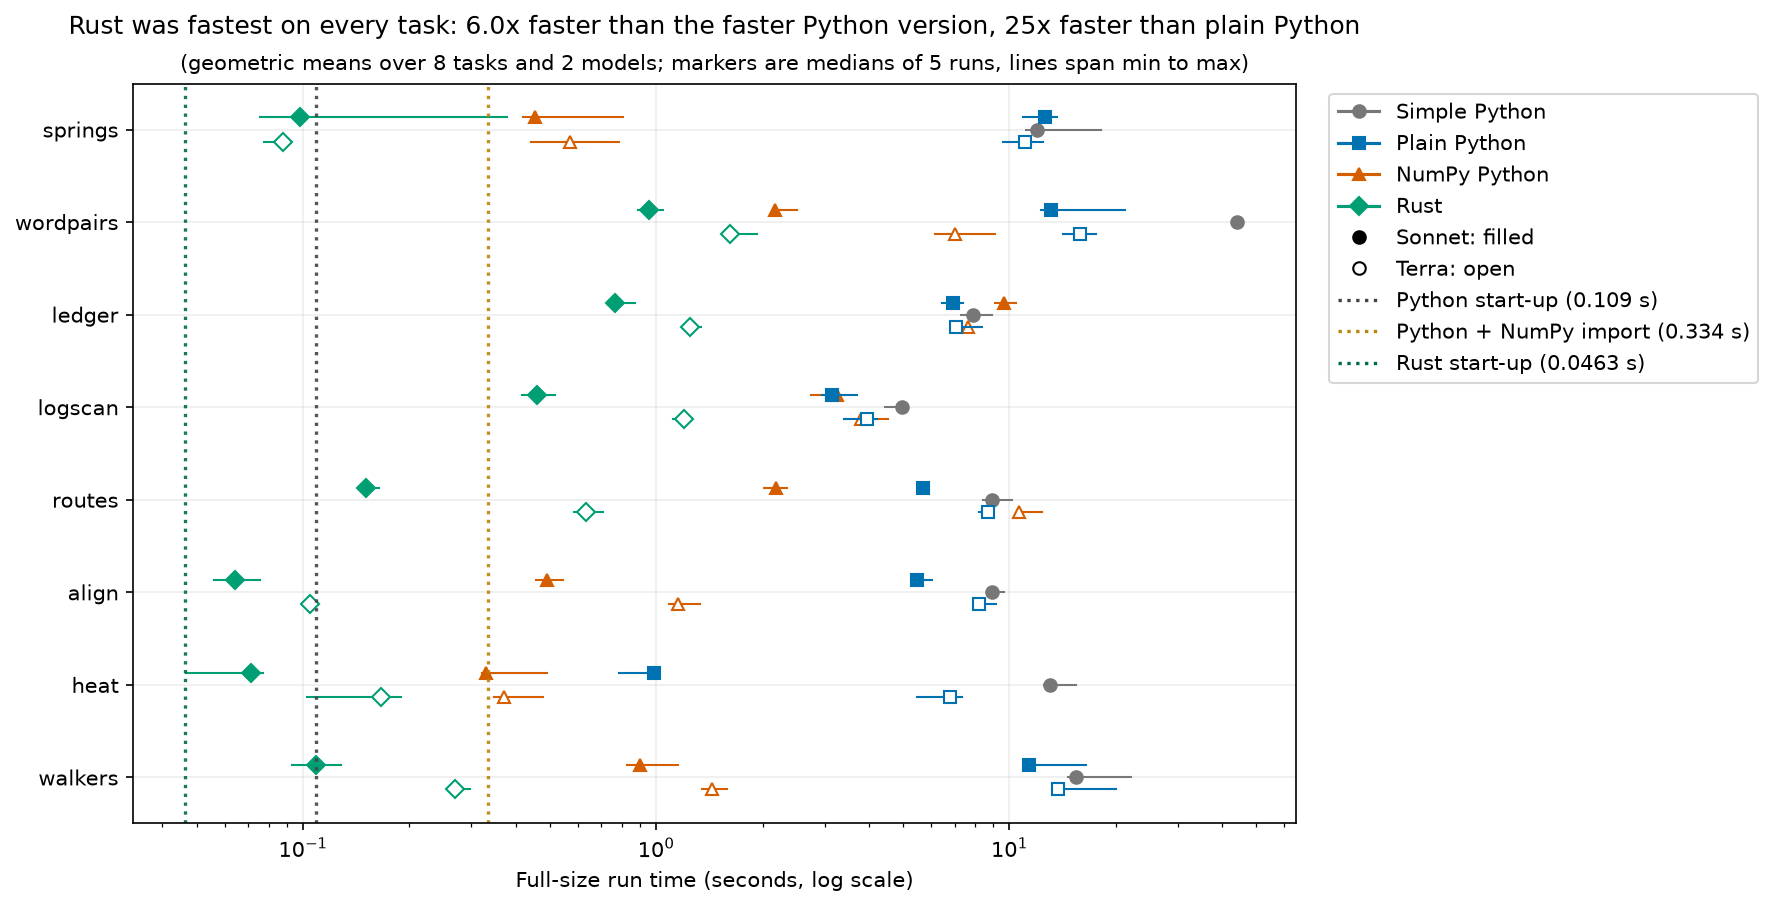

Rust was fastest on every task 16 5.9507507233326935 25.14960937724321


In [14]:
FLOORS = [('simple', 'python', 'Python start-up'), ('fast', 'numpy', 'Python + NumPy import'), ('rust', 'rust', 'Rust start-up')]
FLOOR_COLORS = dict(simple='#444444', fast='#B8860B', rust='#006B4F')
def floor_value(b, metric='wall_seconds'):
    val = baseline[baseline.variant.eq(b)][metric].median()
    return val if metric == 'wall_seconds' else val / 1e6
def floor_lines(ax, metric='wall_seconds', orientation='vertical'):
    for v, b, _ in FLOORS:
        (ax.axvline if orientation == 'vertical' else ax.axhline)(floor_value(b, metric), color=FLOOR_COLORS[v], ls=':', lw=1.6, alpha=.9)
def floor_handles(metric='wall_seconds'):
    names = {'wall_seconds': ['Python start-up', 'Python + NumPy import', 'Rust start-up'], 'peak_working_set': ['Python floor', 'Python + NumPy floor', 'Rust floor']}[metric]
    unit = 's' if metric == 'wall_seconds' else 'MB'
    return [Line2D([0], [0], color=FLOOR_COLORS[v], ls=':', lw=1.6, label=f'{n} ({floor_value(b, metric):.3g} {unit})') for (v, b, _), n in zip(FLOORS, names)]
pair_rows = []
for a in AUTHORS:
    p = median[median.author.eq(a)].pivot(index='task', columns='variant', values='median')
    p['simple'] = median[(median.author == 'reference') & (median.variant == 'simple')].set_index('task')['median']
    for t, r in p.dropna(subset=['plain', 'fast', 'rust']).iterrows():
        pair_rows.append(dict(task=t, author=a, plain=r.plain, fast=r.fast, rust=r.rust, simple=r.simple, best_python=min(r.plain, r.fast)))
pairs = pd.DataFrame(pair_rows)
rust_fastest = (pairs.rust < pairs[['simple', 'plain', 'fast']].min(axis=1))
g_best = geom(pairs.best_python / pairs.rust); g_plain = geom(pairs.plain / pairs.rust)
n_pairs = len(pairs)
lead = 'Rust was fastest on every task' if rust_fastest.all() else f'Rust was fastest on {int(rust_fastest.sum())} of {n_pairs} task-model pairs'
fig, ax = plt.subplots(figsize=(10, 6.4))
for r in median[median.author.isin(AUTHORS + ['reference'])].itertuples():
    y = TASKS.index(r.task) + ({'sonnet': -.13, 'terra': .13, 'reference': 0}[r.author])
    ax.plot([r.min, r.max], [y, y], color=COLORS[r.variant], lw=1)
    ax.plot(r.median, y, marker=MARKERS[r.variant], ms=6, color=COLORS[r.variant], markerfacecolor='white' if r.author == 'terra' else COLORS[r.variant], linestyle='none')
ax.set(xscale='log', yticks=range(len(TASKS)), yticklabels=TASKS, xlabel='Full-size run time (seconds, log scale)')
ax.set_title(f'{lead}: {g_best:.1f}x faster than the faster Python version, {g_plain:.0f}x faster than plain Python', fontsize=12, pad=24)
ax.text(.5, 1.012, '(geometric means over 8 tasks and 2 models; markers are medians of 5 runs, lines span min to max)', transform=ax.transAxes, ha='center', va='bottom', fontsize=10)
floor_lines(ax); ax.invert_yaxis()
ax.legend(handles=legend_handles()+[Line2D([0],[0],marker='o',color='black',ls='',label='Sonnet: filled'), Line2D([0],[0],marker='o',color='black',markerfacecolor='white',ls='',label='Terra: open')]+floor_handles(), bbox_to_anchor=(1.02, 1), loc='upper left')
savefig('runtime_by_task.png')
print(lead, n_pairs, g_best, g_plain)

Rust is the leftmost marker in every row, for both models. The spread within a row shows where the languages
differ most. On springs, align and walkers, the plain-Python markers sit near the simple-Python one at 5 to 16 s,
NumPy pulls back to 0.45 to 1.4 s, and Rust sits between 0.06 and 0.27 s. Heat is similar except that Sonnet's
packed-integer plain Python (0.98 s) is far left of Terra's cell loop (6.8 s). On ledger and logscan all Python
markers cluster at 3 to 10 s, NumPy included, and Rust stands alone at 0.46 to 1.25 s. Wordpairs and routes sit in
between: NumPy helped Sonnet's programs much more than Terra's.

Several Rust markers (springs, heat, align, walkers for Sonnet) lie within two or three times their start-up line,
so a good part of their time is starting the process. Their speed-ups would be larger on bigger inputs (section 13).

## 10. How much faster Rust was

For each task and model, the speed-up of Rust over a Python version is that Python version's median time divided
by Rust's. The table gives the geometric mean over the eight tasks and its 95% bootstrap interval for four
comparisons: simple Python, the model's plain Python, its NumPy Python, and the faster of the two (the lower median
of plain and NumPy for that task). In the figure, each row is one comparison for one model: the small faint markers
are the eight tasks, the large marker is their geometric mean and the bar its interval. The dashed line at 1 would
mean equal speed; everything to its right means Rust was faster.

baseline          Simple Python  Plain Python  NumPy Python  \
task      author                                              
align     sonnet        139.350        85.428         7.632   
          terra          85.153        77.983        10.979   
heat      sonnet        182.388        13.758         4.604   
          terra          78.369        40.701         2.230   
ledger    sonnet         10.314         9.065        12.595   
          terra           6.335         5.676         6.117   
logscan   sonnet         10.829         6.854         7.080   
          terra           4.131         3.275         3.164   
routes    sonnet         59.115        37.742        14.502   
          terra          14.103        13.755        16.780   
springs   sonnet        121.508       128.143         4.616   
          terra         136.180       125.724         6.485   
walkers   sonnet        141.831       103.745         8.258   
          terra          57.576        51.089         5.345   
wordpairs sonnet         46.196        13.736         2.266   
          terra          27.174         9.764         4.314   

baseline          Faster Python version  
task      author                         
align     sonnet                  7.632  
          terra                  10.979  
heat      sonnet                  4.604  
          terra                   2.230  
ledger    sonnet                  9.065  
          terra                   5.676  
logscan   sonnet                  6.854  
          terra                   3.164  
routes    sonnet                 14.502  
          terra                  13.755  
springs   sonnet                  4.616  
          terra                   6.485  
walkers   sonnet                  8.258  
          terra                   5.345  
wordpairs sonnet                  2.266  
          terra                   4.314

,author,comparison,geometric_mean,ci_low,ci_high
0,sonnet,Simple Python,58.307,26.138,118.770
1,sonnet,Plain Python,29.022,13.848,62.723
2,sonnet,NumPy Python,6.672,4.499,9.643
3,sonnet,Faster Python version,6.377,4.423,9.066
4,terra,Simple Python,29.174,12.422,63.710
5,terra,Plain Python,21.794,9.395,50.374
6,terra,NumPy Python,5.746,3.786,8.705
7,terra,Faster Python version,5.553,3.787,8.253


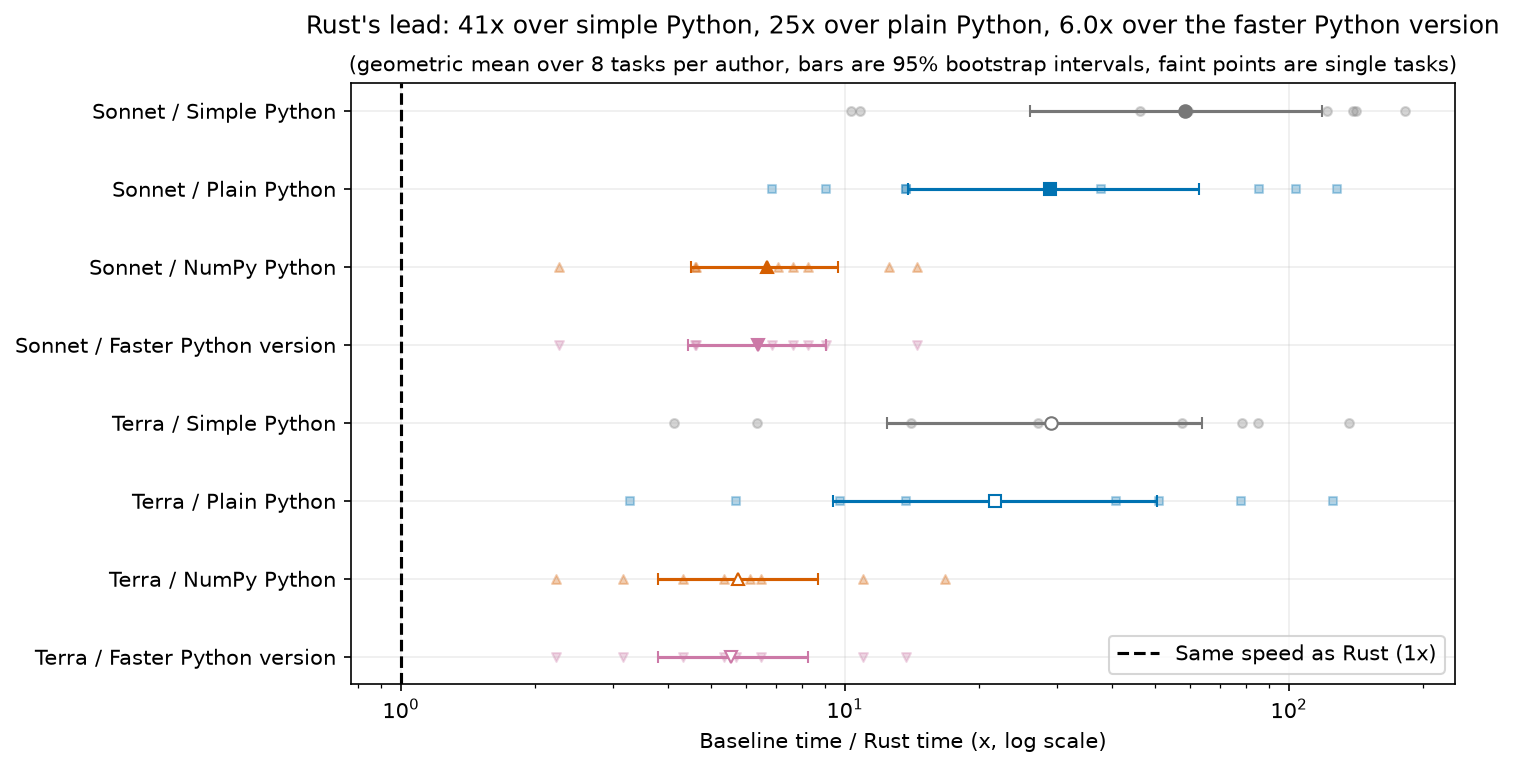

In [15]:
CMP = ['simple', 'plain', 'fast', 'faster']
CMP_LABELS = dict(simple='Simple Python', plain='Plain Python', fast='NumPy Python', faster='Faster Python version')
CMP_COLORS = dict(COLORS, faster='#CC79A7'); CMP_MARKERS = dict(MARKERS, faster='v')
speed_rows = []
for a in AUTHORS:
    rust = median[(median.author == a) & (median.variant == 'rust')].set_index('task')['median']
    d = {v: median[(median.author == ('reference' if v == 'simple' else a)) & (median.variant == v)].set_index('task')['median'] for v in ['simple', 'plain', 'fast']}
    d['faster'] = pd.concat([d['plain'], d['fast']], axis=1).min(axis=1)
    for v in CMP:
        for task, value in (d[v] / rust).dropna().items(): speed_rows.append(dict(author=a, task=task, baseline=v, speedup=value))
speed = pd.DataFrame(speed_rows); rng = np.random.default_rng(39); summaries = []
for a in AUTHORS:
    for v in CMP:
        x = speed[(speed.author == a) & (speed.baseline == v)].speedup.to_numpy(); boot = np.exp(np.log(rng.choice(x, size=(10000, len(x)), replace=True)).mean(axis=1))
        summaries.append(dict(author=a, baseline=v, tasks=len(x), geometric_mean=geom(x), low=np.quantile(boot,.025), high=np.quantile(boot,.975)))
summary = pd.DataFrame(summaries)
out = summary.assign(comparison=summary.baseline.map(CMP_LABELS))[['author', 'comparison', 'geometric_mean', 'low', 'high']].rename(columns={'low': 'ci_low', 'high': 'ci_high'})
out.to_csv(DERIVED / 'speedups.csv', index=False)
speed.assign(comparison=speed.baseline.map(CMP_LABELS))[['task', 'author', 'comparison', 'speedup']].rename(columns={'speedup': 'ratio'}).to_csv(DERIVED / 'speedup_pairs.csv', index=False)
display(speed.pivot(index=['task', 'author'], columns='baseline', values='speedup').reindex(columns=CMP).rename(columns=CMP_LABELS).round(3)); display(out.round(3))
overall = {v: geom(speed[speed.baseline == v].speedup) for v in CMP}
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for i, r in enumerate(summary.itertuples()):
    ax.scatter(speed[(speed.author == r.author) & (speed.baseline == r.baseline)].speedup, [i]*r.tasks, color=CMP_COLORS[r.baseline], alpha=.3, marker=CMP_MARKERS[r.baseline], s=18)
    ax.errorbar(r.geometric_mean, i, xerr=[[r.geometric_mean-r.low], [r.high-r.geometric_mean]], marker=CMP_MARKERS[r.baseline], color=CMP_COLORS[r.baseline], markerfacecolor='white' if r.author == 'terra' else CMP_COLORS[r.baseline], capsize=3, ls='none')
ax.axvline(1, color='black', ls='--', label='Same speed as Rust (1x)')
ax.set(xscale='log', yticks=range(len(summary)), yticklabels=[f"{r['author'].title()} / {CMP_LABELS[r['baseline']]}" for r in summary.to_dict('records')], xlabel='Baseline time / Rust time (x, log scale)')
ax.set_title(f"Rust's lead: {overall['simple']:.0f}x over simple Python, {overall['plain']:.0f}x over plain Python, {overall['faster']:.1f}x over the faster Python version", fontsize=12, pad=24)
ax.text(.5, 1.012, '(geometric mean over 8 tasks per author, bars are 95% bootstrap intervals, faint points are single tasks)', transform=ax.transAxes, ha='center', va='bottom', fontsize=10)
ax.invert_yaxis(); ax.legend(loc='lower right')
savefig('speedup.png')

| Rust compared with | Sonnet | Terra |
|---|---|---|
| Simple Python | 58x (26 to 119) | 29x (12 to 64) |
| Plain Python | 29x (14 to 63) | 22x (9 to 50) |
| NumPy Python | 6.7x (4.5 to 9.6) | 5.8x (3.8 to 8.7) |
| Faster of plain and NumPy | 6.4x (4.4 to 9.1) | 5.6x (3.8 to 8.3) |

The last row is the comparison a developer would make: given both Python versions, pick the faster one, and ask how
much Rust adds on top. The answer is about six times, and at least 2.2 times on every task (Terra's heat, where its
Rust was slow and its NumPy fast). The largest is 14.5x, Sonnet's routes, whose Rust used a bucket queue that suits
the short road lengths.

The plain-Python comparison has wide intervals because the gap depends heavily on the task: Rust was 3 to 14 times
faster than plain Python on the record and text tasks (ledger, logscan, wordpairs), 14 to 38 times on routes, and
51 to 128 times on springs, align and walkers, where plain Python does arithmetic one number at a time. The simple-Python row differs
between the models only because their Rust differs; the simple-Python programs are the same.

## 11. Where NumPy helps

The table divides each model's plain-Python time by its NumPy time for every task. A value above 1 means the NumPy
version was faster than the same model's plain version; below 1 means it was slower.

In [16]:
p = median[median.author.isin(AUTHORS)].pivot(index=['task', 'author'], columns='variant', values='median')
display((p['plain'] / p['fast']).rename('plain / NumPy time').unstack().reindex(TASKS).round(3))

author,sonnet,terra
task,,
springs,27.758,19.388
wordpairs,6.062,2.263
ledger,0.720,0.928
logscan,0.968,1.035
routes,2.603,0.820
align,11.194,7.103
heat,2.988,18.253
walkers,12.563,9.558


NumPy paid off when the work is arithmetic over many numbers at once: springs (19 to 28 times faster than plain),
walkers (10 to 13), align (7 to 11) and, for Terra, heat (18). The spring simulation updates 4,000 masses with the
same formulas at every step; the walkers' random numbers can be generated in blocks; each row of the alignment
table can be computed with array operations.

It did nothing for the parsing tasks. Each JSON line or log line still has to be read by Python code one at a
time, and NumPy can only take over after that: logscan came out at 0.97 and 1.04, and ledger at 0.72 and 0.93, so
both models' NumPy ledger was slower than their plain one. Routes shows the effect of how NumPy is used: Sonnet's
NumPy version was 2.6 times faster than its plain one, Terra's 0.82 times as fast. Section 17 explains both slow
cases. Heat shows the effect of the plain version's quality: against Terra's ordinary cell loop NumPy was 18 times
faster, against Sonnet's packed integer only 3 times.

## 12. Memory

The figure has the same layout as the run-time figure, with peak memory in megabytes (millions of bytes) on a
logarithmic x-axis. The dotted lines are the memory an empty program needs: about 4.5 MB for Rust, 14 MB for
Python and 26 MB for Python with NumPy loaded. Walkers uses the total committed memory of all its processes,
marked with an asterisk.

,task,author,variant,memory_MB,metric
0,align,reference,simple,17.338368,peak working set
1,align,sonnet,fast,27.537408,peak working set
2,align,sonnet,plain,15.593472,peak working set
3,align,sonnet,rust,4.718592,peak working set
4,align,terra,fast,27.656192,peak working set
5,align,terra,plain,15.388672,peak working set
6,align,terra,rust,4.591616,peak working set
7,heat,reference,simple,39.895040,peak working set
8,heat,sonnet,fast,37.040128,peak working set
9,heat,sonnet,plain,25.251840,peak working set


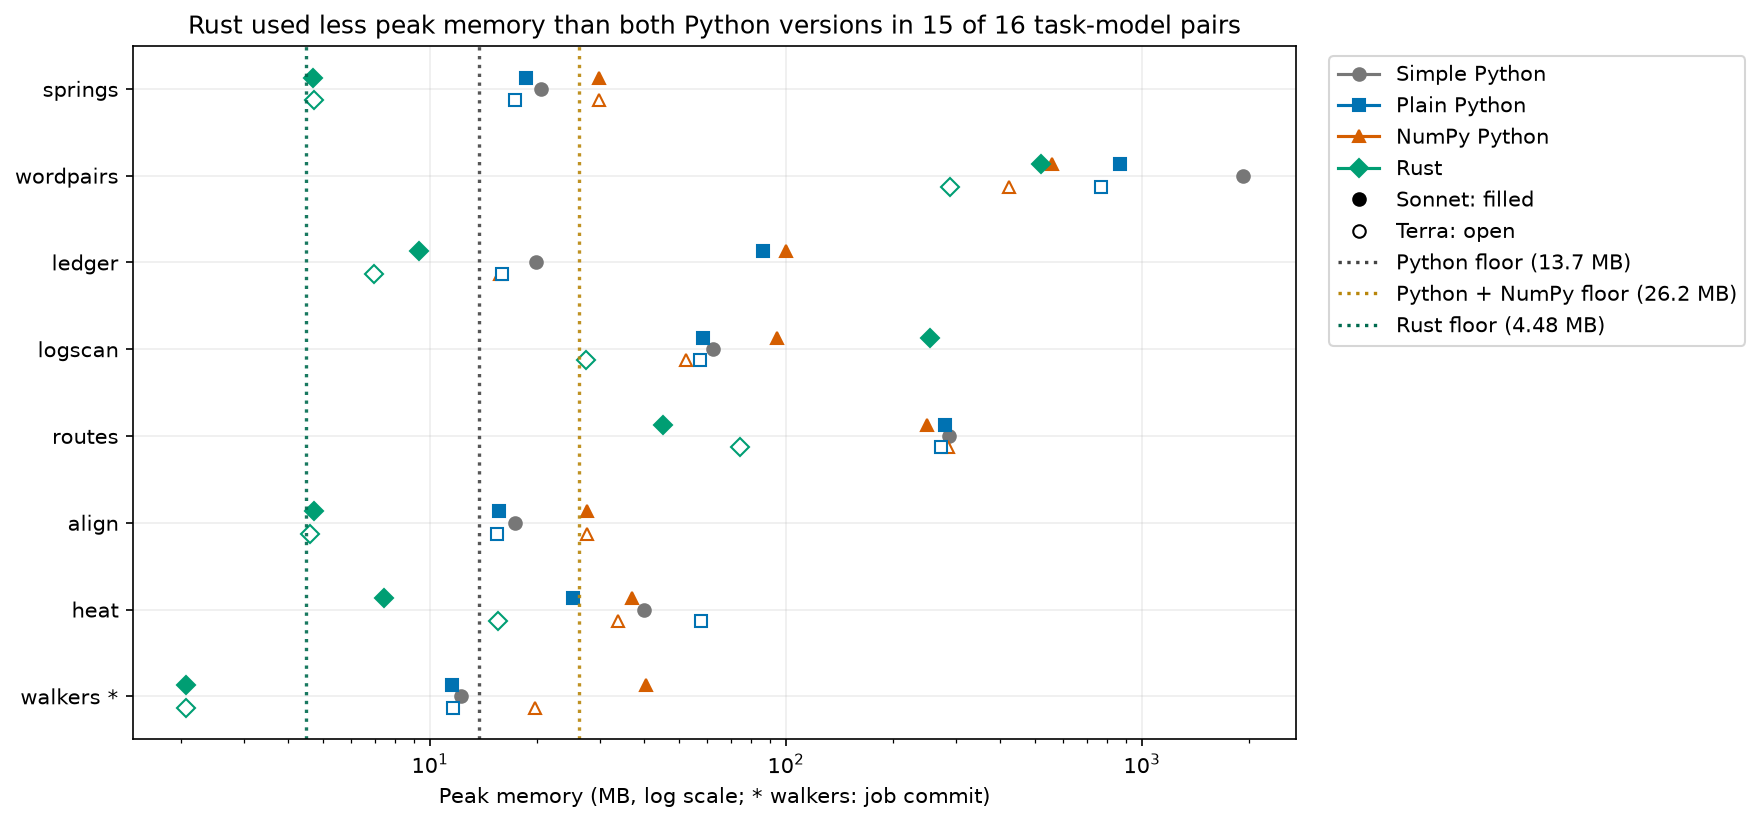

15 16


In [17]:
mem = full[full.author.isin(AUTHORS + ['reference'])].copy(); mem['memory_MB'] = np.where(mem.task.eq('walkers'), mem.peak_job_commit, mem.peak_working_set) / 1e6
memory = mem.groupby(['task', 'author', 'variant']).memory_MB.median().reset_index(); memory['metric'] = np.where(memory.task.eq('walkers'), 'peak job commit', 'peak working set')
memory.to_csv(DERIVED / 'memory.csv', index=False); display(memory)
mp = memory[memory.author.isin(AUTHORS)].pivot_table(index=['task', 'author'], columns='variant', values='memory_MB')
n_less = int((mp.rust < mp[['plain', 'fast']].min(axis=1)).sum()); n_mem = len(mp)
fig, ax = plt.subplots(figsize=(10, 6))
for r in memory.itertuples():
    y = TASKS.index(r.task) + {'sonnet': -.13, 'terra': .13, 'reference': 0}[r.author]
    ax.plot(r.memory_MB, y, marker=MARKERS[r.variant], color=COLORS[r.variant], markerfacecolor='white' if r.author == 'terra' else COLORS[r.variant], ls='none')
floor_lines(ax, 'peak_working_set'); ax.set(xscale='log', yticks=range(8), yticklabels=[t + (' *' if t == 'walkers' else '') for t in TASKS], xlabel='Peak memory (MB, log scale; * walkers: job commit)')
ax.set_title(f'Rust used less peak memory than both Python versions in {n_less} of {n_mem} task-model pairs', fontsize=12); ax.invert_yaxis()
ax.legend(handles=legend_handles()+[Line2D([0],[0],marker='o',color='black',ls='',label='Sonnet: filled'), Line2D([0],[0],marker='o',color='black',markerfacecolor='white',ls='',label='Terra: open')]+floor_handles('peak_working_set'), bbox_to_anchor=(1.02,1), loc='upper left')
savefig('memory_by_task.png')
print(n_less, n_mem)

Rust used less memory than both of the same model's Python versions in 15 of the 16 pairs; against the faster
Python version it needed 3.8 times less for Sonnet and 3.4 times less for Terra (geometric means). On small-data
tasks (springs, align, heat) the difference is mostly the interpreter itself: Rust needed 4.6 to 16 MB, Python 15
to 58 MB.

The larger differences come from how Python stores data. Every Python integer and string is a separate object
with its own bookkeeping, so the simple solution of wordpairs, which keeps a dictionary of about 4 million word
pairs as tuples of strings, peaked at 1.9 GB. The models' plain versions stored each pair as one packed integer
and needed 770 to 870 MB; their Rust needed 290 and 520 MB.

The exception is Sonnet's Rust log scanner, which read the whole 228 MB log into memory before parsing and peaked
at 253 MB, four times its plain Python (59 MB). Terra's Rust read the file line by line and needed 28 MB. Memory
depends on such choices as much as on the language.

## 13. Small inputs and start-up time

Wordpairs, routes and heat were also run at 1/256, 1/64, 1/16 and 1/4 of the benchmark size, three timed runs
each. In the figure, each panel is one task, with input size and run time on logarithmic axes. Solid lines are
Sonnet and the simple-Python reference, dashed lines Terra; the dotted horizontal lines are the start-up times. The
first table gives each program's slope between the two largest sizes (1 means time grows in proportion to input;
near 0 means the time is mostly fixed cost). The second gives Rust's time divided by plain Python's at each size.

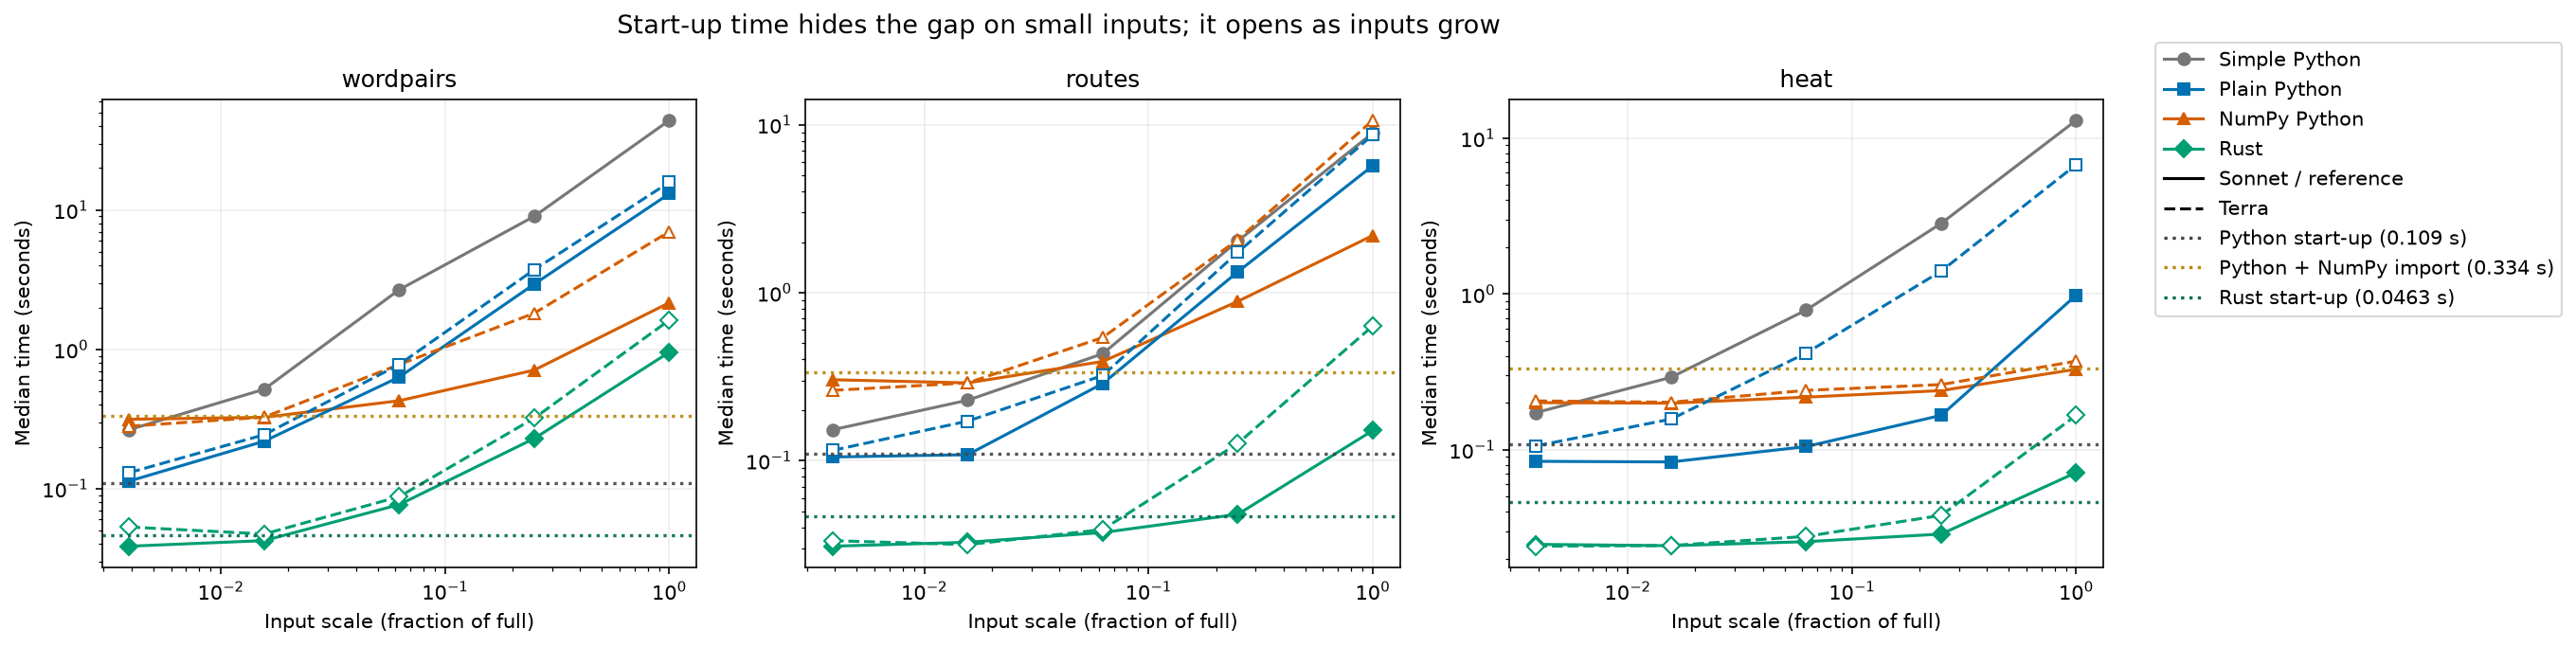

,task,author,variant,slope
0,heat,reference,simple,1.099
1,heat,sonnet,fast,0.228
2,heat,sonnet,plain,1.282
3,heat,sonnet,rust,0.656
4,heat,terra,fast,0.250
5,heat,terra,plain,1.135
6,heat,terra,rust,1.066
7,routes,reference,simple,1.069
8,routes,sonnet,fast,0.652
9,routes,sonnet,plain,1.050


,task,author,scale,Rust / plain time
0,heat,sonnet,0.0039,0.2931
1,heat,sonnet,0.0156,0.2899
2,heat,sonnet,0.0625,0.2452
3,heat,sonnet,0.2500,0.1729
4,heat,sonnet,1.0000,0.0727
5,heat,terra,0.0039,0.2270
6,heat,terra,0.0156,0.1542
7,heat,terra,0.0625,0.0665
8,heat,terra,0.2500,0.0270
9,heat,terra,1.0000,0.0246


In [18]:
sw = pd.concat([sweep, runs[runs.task.isin(['wordpairs','routes','heat']) & runs.input.eq('full')]], ignore_index=True)
sw = sw[sw.author.isin(AUTHORS + ['reference']) & sw.status.eq('correct')].merge(ok, on=['author','task','variant'])
sw['scale'] = sw.apply(lambda r: entries[r.task, r.input]['scale'], axis=1)
sm = sw.groupby(['task','author','variant','scale']).wall_seconds.median().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, task in zip(axes, ['wordpairs','routes','heat']):
    for (a,v), g in sm[sm.task.eq(task)].groupby(['author','variant']):
        g = g.sort_values('scale'); ax.plot(g.scale, g.wall_seconds, marker=MARKERS[v], color=COLORS[v], markerfacecolor='white' if a == 'terra' else COLORS[v], ls='--' if a == 'terra' else '-')
    floor_lines(ax, orientation='horizontal'); ax.set(xscale='log', yscale='log', title=task, xlabel='Input scale (fraction of full)', ylabel='Median time (seconds)')
fig.legend(handles=legend_handles()+[Line2D([0],[0],color='black',label='Sonnet / reference'), Line2D([0],[0],color='black',ls='--',label='Terra')]+floor_handles(), bbox_to_anchor=(1.01,.95), loc='upper left'); fig.suptitle('Start-up time hides the gap on small inputs; it opens as inputs grow', fontsize=13); fig.tight_layout(); savefig('size_sweep.png')
slopes = []
for (t,a,v), g in sm.groupby(['task','author','variant']):
    g = g.sort_values('scale').tail(2)
    if len(g)==2: slopes.append(dict(task=t, author=a, variant=v, slope=np.log(g.wall_seconds.iloc[1]/g.wall_seconds.iloc[0])/np.log(g.scale.iloc[1]/g.scale.iloc[0])))
display(pd.DataFrame(slopes).round(3))
sp = sm[sm.author.isin(AUTHORS)].pivot(index=['task','author','scale'], columns='variant', values='wall_seconds')
display((sp.rust / sp.plain).rename('Rust / plain time').reset_index().round(4))

At 1/256 of the benchmark size every version finishes within a few tenths of a second, and the ranking is mostly
about start-up: Rust at 0.02 to 0.05 s, plain Python at 0.08 to 0.15 s, NumPy Python at 0.2 to 0.3 s because
importing NumPy alone costs about 0.2 s. Rust was then only 2.5 to 4.4 times faster than the faster Python version,
and plain Python beat NumPy Python on all three tasks.

As inputs grow the lines separate. On heat, Rust's time divided by plain Python's fell from 0.23 to 0.29 at the
smallest size (Rust 3 to 4 times faster) to 0.073 for Sonnet and 0.025 for Terra at full size (14 and 41 times). Some slopes
are well below 1 even at full size, such as Sonnet's NumPy heat (0.23) and Rust heat (0.66): those programs are
still mostly start-up at the benchmark size, which is why the speed-ups in section 10 understate what Rust gains on
long jobs. For a script that handles small files, start-up time can matter more than the language.

## 14. More cores

The walkers task asks for the walks to be split over a given number of workers. Each program ran with 1, 2, 4, 8
and 16 workers, three timed runs each. The left panel shows median run time (log scale); the right panel shows each
program's speed-up over its own one-worker time, with the dotted diagonal as a perfect speed-up and the vertical
line at the laptop's six performance cores. The table also gives the CPU time divided by wall time, which counts
how many cores were busy on average.

,author,variant,workers,time,cpu_wall,speedup
0,reference,simple,1,16.861,0.983,1.000
1,reference,simple,2,8.542,1.937,1.974
2,reference,simple,4,4.793,3.709,3.518
3,reference,simple,8,2.908,7.173,5.798
4,reference,simple,16,2.348,13.028,7.180
5,sonnet,fast,1,0.736,0.941,1.000
6,sonnet,fast,2,0.654,1.667,1.127
7,sonnet,fast,4,0.644,2.810,1.144
8,sonnet,fast,8,0.633,5.480,1.164
9,sonnet,fast,16,0.675,5.418,1.091


6 0.6751712999976007 0.2601450999936787 True


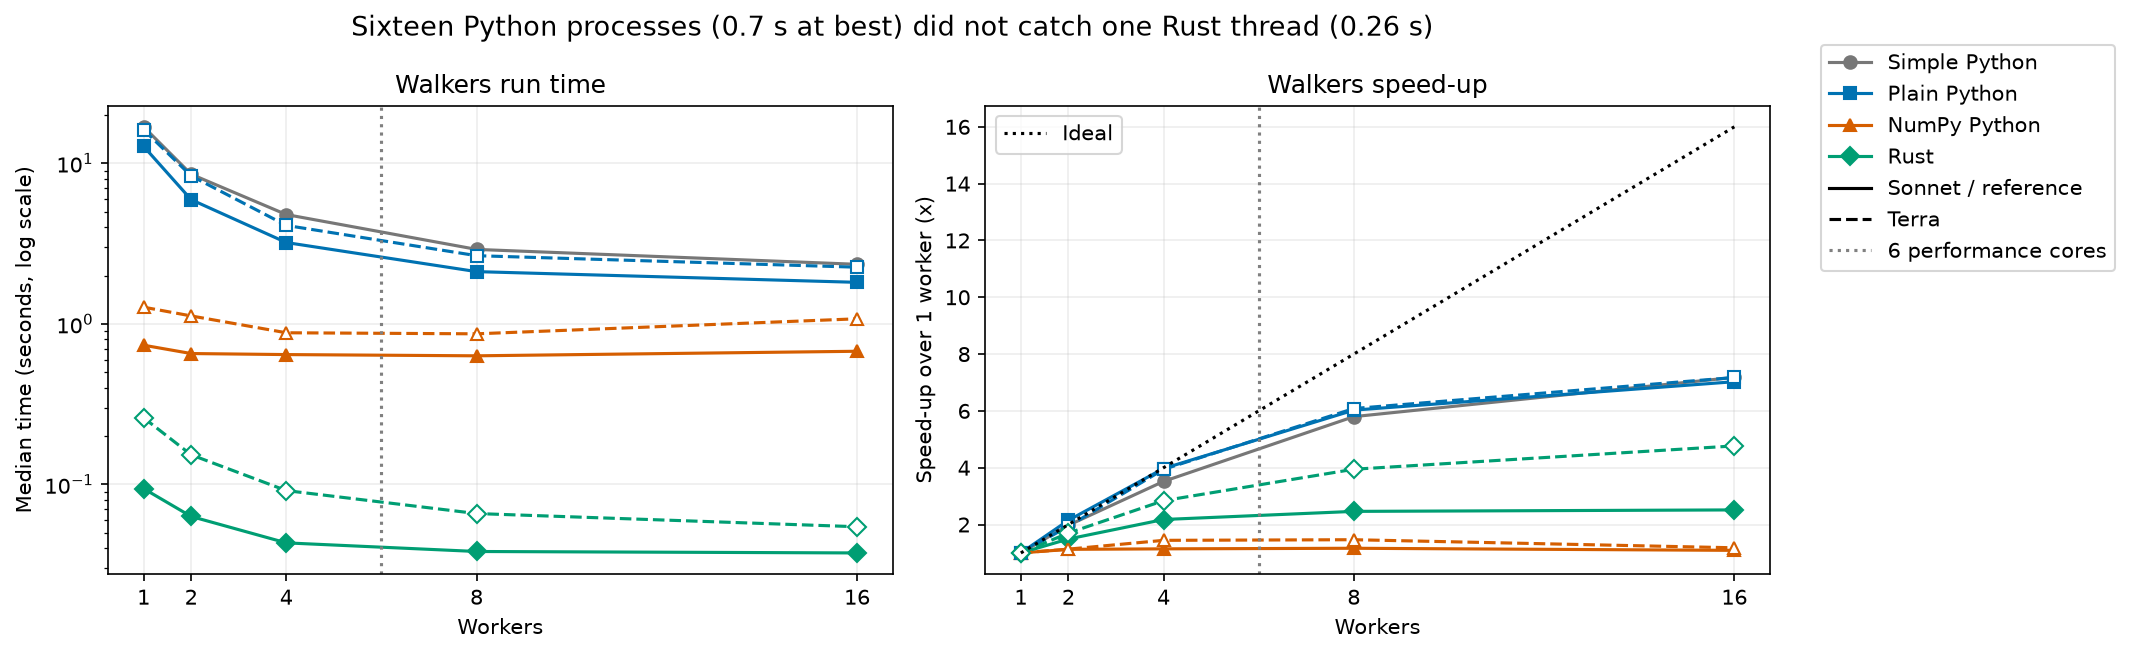

In [19]:
sc = scaling[scaling.status.eq('correct')].merge(ok, on=['author','task','variant'])
scm = sc.groupby(['author','variant','workers']).agg(time=('wall_seconds','median'), cpu_wall=('cpu_wall_ratio','median')).reset_index()
scm['speedup'] = scm.apply(lambda r: scm.loc[(scm.author==r.author)&(scm.variant==r.variant)&(scm.workers==1), 'time'].iloc[0]/r.time if ((scm.author==r.author)&(scm.variant==r.variant)&(scm.workers==1)).any() else np.nan, axis=1)
display(scm.round(3))
n_pcores = len(machine['p_cores']) // 2   # P-cores have two threads each
t16 = scm[(scm.workers == 16) & scm.variant.ne('rust')].time.min()
r1 = scm[(scm.workers == 1) & scm.variant.eq('rust') & scm.author.isin(AUTHORS)].time.max()
print(n_pcores, t16, r1, t16 > r1)
fig, axes = plt.subplots(1,2,figsize=(12,4.4))
for (a,v), g in scm.groupby(['author','variant']):
    g=g.sort_values('workers')
    for ax, col in zip(axes,['time','speedup']): ax.plot(g.workers,g[col],marker=MARKERS[v],color=COLORS[v],markerfacecolor='white' if a=='terra' else COLORS[v],ls='--' if a=='terra' else '-')
axes[0].set(yscale='log', ylabel='Median time (seconds, log scale)', title='Walkers run time'); axes[1].plot([1,16],[1,16],color='black',ls=':',label='Ideal'); axes[1].set(ylabel='Speed-up over 1 worker (x)',title='Walkers speed-up'); axes[1].legend(loc='upper left')
for ax in axes: ax.axvline(n_pcores,color='gray',ls=':'); ax.set(xlabel='Workers',xticks=[1,2,4,8,16])
claim = f'Sixteen Python processes ({t16:.1f} s at best) did not catch one Rust thread ({r1:.2f} s)' if t16 > r1 else f'Sixteen Python processes ({t16:.1f} s at best) beat one Rust thread ({r1:.2f} s)'
fig.suptitle(claim, fontsize=13)
fig.legend(handles=legend_handles()+[Line2D([0],[0],color='black',label='Sonnet / reference'),Line2D([0],[0],color='black',ls='--',label='Terra'),Line2D([0],[0],color='gray',ls=':',label=f'{n_pcores} performance cores')],bbox_to_anchor=(1.01,.95),loc='upper left'); fig.tight_layout(); savefig('walkers_scaling.png')

The standard Python build cannot run Python code on several cores within one process, so both models' plain
versions started one process per worker. They scaled well up to four workers and reached about 7 times at 16
(Sonnet: 12.7 s to 1.8 s), with 12.7 cores busy on average. The NumPy versions barely changed (at most 1.5 times):
they took 0.74 and 1.27 s on one worker, and starting extra Python processes, each importing NumPy, cost about as
much as it saved. Rust threads start cheaply, but Rust's one-worker times (0.094 and 0.26 s) were already close to
the start-up floor, so 16 threads gained 2.5 and 4.7 times.

Even with 16 processes, the fastest Python program (0.68 s) was slower than either model's Rust on one thread.
Using every core helps Python, but on this task it did not make up for the interpreter.

## 15. Code size and build time

The left panel counts lines of code per program, without blank lines and comments (the simple reference is left
out because its file holds all eight tasks). The right panel shows each Rust program's build time from clean
(median of three) and after a one-line change.

,task,author,variant,code_lines
0,springs,sonnet,rust,61
1,springs,sonnet,plain,42
2,springs,sonnet,fast,47
3,wordpairs,sonnet,rust,212
4,wordpairs,sonnet,plain,64
5,wordpairs,sonnet,fast,178
6,ledger,sonnet,rust,395
7,ledger,sonnet,plain,85
8,ledger,sonnet,fast,129
9,logscan,sonnet,rust,246


,task,author,status,clean_median,incremental_seconds,crates_kept
0,springs,sonnet,ok,4.611792,4.627016,[]
1,wordpairs,sonnet,ok,3.816125,3.560294,[]
2,ledger,sonnet,ok,4.770767,5.614717,[]
3,logscan,sonnet,ok,5.268264,8.188804,[]
4,routes,sonnet,ok,3.902824,3.233412,[]
5,align,sonnet,ok,3.519611,4.037226,[]
6,heat,sonnet,ok,4.825867,3.626199,[]
7,walkers,sonnet,ok,5.442664,6.367622,[]
8,springs,terra,ok,2.626941,1.415928,[]
9,wordpairs,terra,ok,2.220727,12.813268,[]


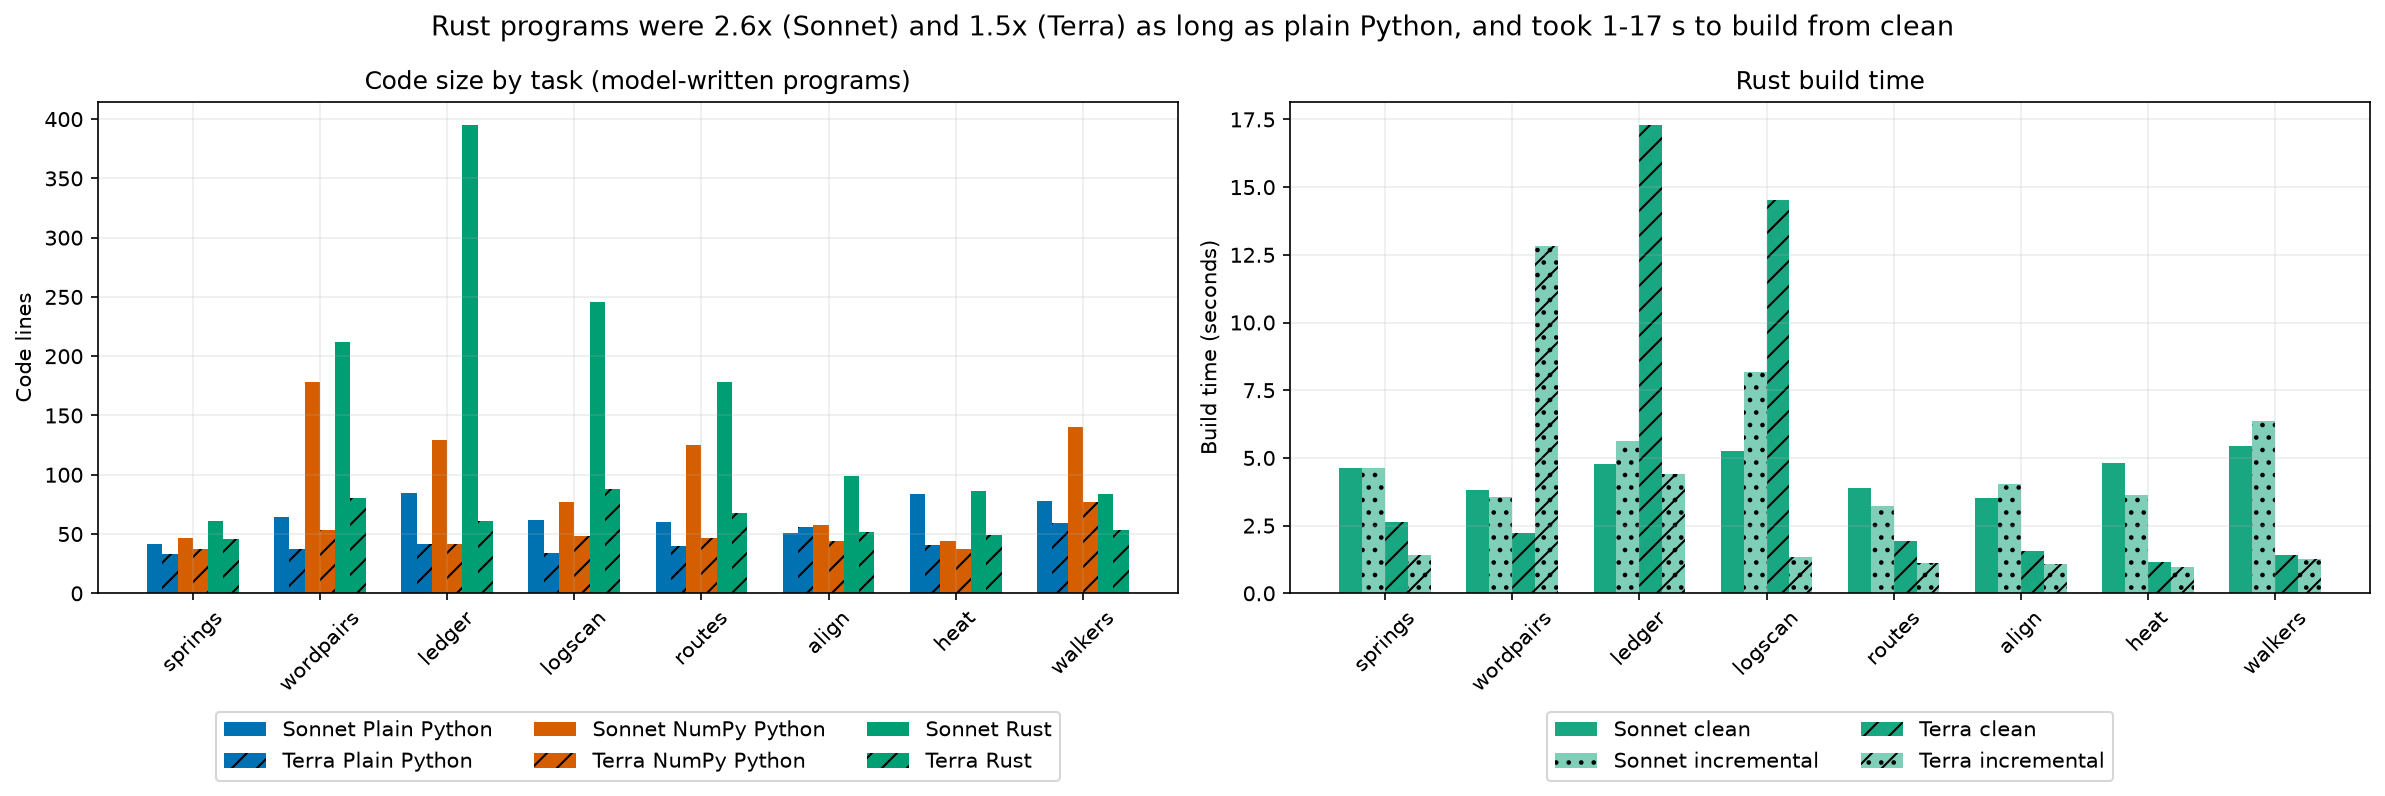

2.58745247148289 1.4532163742690059 1.1740645999961998 17.292876299994532


In [20]:
loc_main = loc[loc.author.isin(AUTHORS + ['reference'])].copy()
build_main = builds[builds.author.isin(AUTHORS)].copy()
build_main['clean_median'] = build_main.clean_seconds.map(lambda x: np.median(json.loads(x)) if isinstance(x,str) and json.loads(x) else np.nan)
display(loc_main[['task','author','variant','code_lines']]); display(build_main[['task','author','status','clean_median','incremental_seconds','crates_kept']])
lines_total = loc_main[loc_main.author.isin(AUTHORS)].groupby(['author', 'variant']).code_lines.sum()
r_s = lines_total['sonnet', 'rust'] / lines_total['sonnet', 'plain']; r_t = lines_total['terra', 'rust'] / lines_total['terra', 'plain']
lo, hi = build_main.clean_median.min(), build_main.clean_median.max()
fig, axes = plt.subplots(1,2,figsize=(16,5.6)); x=np.arange(len(TASKS)); width=.12
series = [(a,v) for v in ['plain','fast','rust'] for a in AUTHORS]
for i,(a,v) in enumerate(series):
    d=loc_main[(loc_main.author==a)&(loc_main.variant==v)].set_index('task').code_lines.reindex(TASKS)
    axes[0].bar(x+(i-2.5)*width,d,width,color=COLORS[v],hatch='//' if a=='terra' else '',label=f'{a.title()} {LABELS[v]}')
axes[0].set(xticks=x,xticklabels=TASKS,ylabel='Code lines',title='Code size by task (model-written programs)'); axes[0].tick_params(axis='x',rotation=45)
for i,(a,col) in enumerate([(a,col) for a in AUTHORS for col in ['clean_median','incremental_seconds']]):
    d=build_main[build_main.author.eq(a)].set_index('task')[col].reindex(TASKS)
    axes[1].bar(x+(i-1.5)*.18,d,.18,color=COLORS['rust'],hatch=('//' if a=='terra' else '') + ('..' if col.startswith('incremental') else ''),alpha=.9 if col.startswith('clean') else .5,label=f'{a.title()} {"clean" if col.startswith("clean") else "incremental"}')
axes[1].set(xticks=x,xticklabels=TASKS,ylabel='Build time (seconds)',title='Rust build time'); axes[1].tick_params(axis='x',rotation=45)
axes[0].legend(fontsize=10,bbox_to_anchor=(.5,-.22),loc='upper center',ncol=3); axes[1].legend(fontsize=10,bbox_to_anchor=(.5,-.22),loc='upper center',ncol=2)
fig.suptitle(f'Rust programs were {r_s:.1f}x (Sonnet) and {r_t:.1f}x (Terra) as long as plain Python, and took {lo:.0f}-{hi:.0f} s to build from clean', fontsize=13)
fig.tight_layout(); savefig('code_and_build.png')
print(r_s, r_t, lo, hi)

Rust programs were longer: Sonnet's eight Rust programs had 1,361 lines against 526 for its plain Python (2.6
times) and Terra's 497 against 342 (1.5 times). Most of the difference is in the parsing tasks. Sonnet wrote its
own JSON reader for ledger (395 lines) and its own log-line checker for logscan (246 lines) instead of using the
allowed serde_json and regex libraries; Terra used the libraries and wrote 61 and 88 lines. Those libraries cost
build time: Terra's ledger and logscan took 17 s and 15 s to build from clean, against 1 to 3 s for its other
programs. Sonnet turned on whole-program optimisation for all eight programs, and its builds took 3.5 to 5.4 s
each; Terra kept the defaults. One incremental rebuild (Terra's wordpairs, 12.8 s) took longer than the same
program's clean builds, which points to the busy machine rather than the compiler. Python needs no build step.

## 16. The two models, and two larger models on heat

The first table divides Sonnet's median time by Terra's for each task and version; below 1 means Sonnet's program
was faster. The second compares the heat programs of all four models, including those by Claude Opus 5.5 and
GPT-6.1 Sol.

In [21]:
a = median[median.author.isin(AUTHORS)].pivot(index=['task','variant'],columns='author',values='median').dropna()
a['Sonnet / Terra'] = a.sonnet/a.terra; a['faster'] = np.where(a['Sonnet / Terra']<1,'Sonnet',np.where(a['Sonnet / Terra']>1,'Terra','tie'))
display(a.round(3)); display(a.groupby('variant')['Sonnet / Terra'].agg(geom).rename('geometric mean'))

author             sonnet   terra  Sonnet / Terra  faster
task      variant                                        
align     fast      0.489   1.152           0.425  Sonnet
          plain     5.478   8.183           0.669  Sonnet
          rust      0.064   0.105           0.611  Sonnet
heat      fast      0.329   0.371           0.887  Sonnet
          plain     0.983   6.771           0.145  Sonnet
          rust      0.071   0.166           0.430  Sonnet
ledger    fast      9.635   7.619           1.265   Terra
          plain     6.934   7.069           0.981  Sonnet
          rust      0.765   1.245           0.614  Sonnet
logscan   fast      3.248   3.805           0.854  Sonnet
          plain     3.144   3.939           0.798  Sonnet
          rust      0.459   1.203           0.381  Sonnet
routes    fast      2.190  10.621           0.206  Sonnet
          plain     5.699   8.707           0.655  Sonnet
          rust      0.151   0.633           0.239  Sonnet
springs   fast      0.454   0.569           0.798  Sonnet
          plain    12.608  11.038           1.142   Terra
          rust      0.098   0.088           1.121   Terra
walkers   fast      0.901   1.437           0.627  Sonnet
          plain    11.321  13.733           0.824  Sonnet
          rust      0.109   0.269           0.406  Sonnet
wordpairs fast      2.163   7.001           0.309  Sonnet
          plain    13.112  15.845           0.828  Sonnet
          rust      0.955   1.623           0.588  Sonnet

variant
fast     0.580912
plain    0.666270
rust     0.500344
Name: geometric mean, dtype: float64

In [22]:
if {'opus','sol'}.issubset(set(median[median.task.eq('heat')].author)):
    display(median[(median.task=='heat') & median.author.isin(['opus','sol','sonnet','terra'])].pivot(index='variant',columns='author',values='median').reindex(['plain','fast','rust']).round(4))
else: print('Opus and Sol pilot programs were not both measured.')

author,opus,sol,sonnet,terra
variant,,,,
plain,0.5876,0.8605,0.9835,6.7714
fast,0.3460,0.3682,0.3291,0.3710
rust,0.0373,0.0419,0.0715,0.1664


Sonnet's Rust was faster than Terra's on seven of the eight tasks, by 1.6 to 4.2 times, and its plain Python on
seven (on ledger by only 2%). Terra's Rust springs was 10% faster than Sonnet's, which is within the noise. Sonnet made more specialised
choices: a bucket queue instead of a general priority queue for routes, a rewritten alignment recurrence, the
packed-integer heat grid and hand-written parsers. Terra wrote plainer programs closer to the textbook method. Both
styles gave correct programs; the extra effort bought speed. One program per model and task is a small sample of
each model's behaviour, so these differences describe these 16 sessions, not the models in general.

The two larger models wrote faster heat programs: Opus 5.5 took 0.037 s in Rust, 0.35 s in NumPy and 0.59 s in
plain Python (also a packed integer), and Sol 0.042, 0.37 and 0.86 s. Their Rust was about 9 times faster than
their faster Python version, against 4.6x for Sonnet and 2.2x for Terra on the same task. On one task, the speed-up
from Rust ranged from 2.2x to 9x depending on the model, a wider spread than the interval of the headline average.

## 17. Error analysis: slow choices, not wrong answers

No program gave a wrong answer, so this section looks at the next most useful thing: programs that were correct but
slower or larger than they needed to be, and why. The cases are all the large anomalies in the tables above, found
by comparing each model's versions with each other and with the other model's.

**Terra's NumPy routes was slower than its plain version (10.6 s against 8.7 s).** The two files differ only in how
they read the road list:

In [23]:
show_code('terra', 'routes', 'fast', 7, 21)

   7      with open(sys.argv[1], 'rb') as f:
   8          n, m, q = map(int, f.readline().split())
   9          data = np.fromstring(f.read(), dtype=np.int64, sep=' ')
  10      edges = data[:3*m].reshape(m, 3)
  11      # Convert once to native integers so the graph traversal avoids NumPy scalar overhead.
  12      us = edges[:, 0].tolist()
  13      vs = edges[:, 1].tolist()
  14      ws = edges[:, 2].tolist()
  15      sources = data[3*m:3*m+q].tolist()
  16      del edges, data
  17      adj = [[] for _ in range(n)]
  18      for u, v, w in zip(us, vs, ws):
  19          adj[u].append((v, w))
  20          adj[v].append((u, w))
  21      del us, vs, ws


The NumPy version reads the 2.7 million numbers with `np.fromstring(text, sep=" ")`, then converts them back to
ordinary Python lists for the shortest-path search, which is the same code in both versions. Timed separately on the
benchmark input (2026-10-30), that NumPy call took 2.43 s, where splitting the text and converting with `int` took
0.32 s. NumPy's text parser is slower than Python's own here, and the search, which is most of the work, cannot use
arrays. Sonnet's NumPy routes (2.2 s) used NumPy throughout: it parsed the digits with array operations, stored the network
as flat arrays, and ran the search in batches that relax many roads per array operation.

**Both models' NumPy ledger was slower than their plain version.** Sonnet's two ledger programs read the file the
same way: each block of lines becomes one JSON array, parsed with a single `json.loads` call. The plain version
then adds each transaction straight into dictionaries. The NumPy version first copies the parsed fields of the
block into NumPy arrays:

In [24]:
show_code('sonnet', 'ledger', 'fast', 103, 122)

 103              objs = loads(b"[" + block.replace(b"\n", b",") + b"]")
 104              sgn = np.fromiter(map(sign_of, map(g_type, objs)), dtype=np.int64, count=len(objs))
 105              test = np.fromiter(map(contains, map(g_tags, objs), repeat("test")), dtype=np.bool_, count=len(objs))
 106              keep = ((sgn != 0) & ~test)
 107              n = int(keep.sum())
 108              if n == 0:
 109                  continue
 110              klist = keep.tolist()
 111              if n != len(objs):
 112                  objs = list(compress(objs, klist))
 113                  sgn = sgn[keep]
 114              amounts = list(map(g_amount, objs))
 115              currs = map(g_curr, objs)
 116              accs = list(map(g_acc, objs))
 117              chs = list(map(g_chan, map(g_meta, objs)))
 118              rate = np.fromiter(map(rates.__getitem__, currs), dtype=np.int64, count=n)
 119              vals = (hundredths(amounts) * rate // 1000000) * sgn
 120              

Parsing is most of the time, and NumPy cannot speed it up; the copying with `np.fromiter` and the grouped sums are
extra work on top, so the NumPy version took 9.6 s against 6.9 s. Terra's NumPy ledger said in its summary that
NumPy "offers little advantage for this string-heavy, irregular input" and used the same approach as its plain
version, which was then 8% slower because of NumPy's import time and the noise. A model that recognises when NumPy
does not apply does better than one that applies it anyway.

**Terra's heat was slower in Rust and in plain Python than Sonnet's.** Terra's programs store, for every open cell,
the positions of its four neighbours, and the update loop looks them up one by one:

In [25]:
show_code('terra', 'heat', 'plain', 24, 31)

  24      for _ in range(steps):
  25          changed = False
  26          for i, u, d, l, r in cells:
  27              v = (4 * values[i] + values[u] + values[d] + values[l] + values[r]) >> 3
  28              other[i] = v
  29              changed |= v != values[i]
  30          values, other = other, values
  31          if not changed:


That is a sound general method, but the lookups jump around in memory, so the Rust compiler cannot process several
cells per instruction as it can with Sonnet's padded grid. Terra's Rust took 0.166 s against 0.071 s, and the same
loop in plain Python took 6.8 s, where Sonnet's packed integer took 0.98 s. Terra's programs also stop early when
the grid stops changing, which is correct but never happened on these inputs.

**Sonnet's Rust log scanner used four times the memory of its Python.** It reads the whole 228 MB file with one
call (`std::fs::read`) before parsing it, which is simple and fast (0.46 s, the fastest logscan) but holds the entire
file in memory. For a log larger than the machine's memory, that program would fail where the line-by-line
programs would not.

**Sonnet's Rust springs had one slow run.** Its five runs ranged from 0.076 to 0.379 s. The program is the same
every time, so the spread comes from the machine, not from the code; the median (0.098 s) is barely affected.

## 18. Measurement quality

The laptop was running other work during the timing: other agent sessions, a browser, the ChatGPT app and
antivirus scanning. Each run recorded how many cores the rest of the machine kept busy (`other_busy_cores`: busy
CPU time on the whole machine minus the program's own, divided by its wall time). The cell prints the coefficient
of variation of each program's repeats (standard deviation divided by mean), the distribution of
`other_busy_cores` per table, and the runs with heavy outside load or a single-threaded program using more than one
core.

In [26]:
quality_tables = {'correctness': correctness, 'runs': runs, 'sweep': sweep, 'scaling': scaling, 'baseline': baseline}
cv = full.groupby(['task','author','variant']).wall_seconds.agg(['mean','std','count']); cv['CV'] = cv['std']/cv['mean']; display(cv.round(4).to_string())
display(pd.DataFrame({name: {'median': d.other_busy_cores.median(), 'max': d.other_busy_cores.max()} for name,d in quality_tables.items()}).T.round(3))
for name,d in quality_tables.items():
    flagged = d[(d.other_busy_cores > 2) | ((d.get('workers',pd.Series(1,index=d.index)) == 1) & (d.cpu_wall_ratio > 1.2))]
    print(name, 'flagged rows:', len(flagged))
    print(flagged[[c for c in ['author','task','variant','input','workers','repeat','other_busy_cores','cpu_wall_ratio'] if c in flagged]].to_string(index=False))
display(pd.DataFrame(exclusions).groupby(['table','reason']).size().rename('excluded rows'))

'                                mean     std  count      CV\ntask      author    variant                                \nalign     reference simple    9.1433  0.4741      5  0.0518\n          sonnet    fast      0.4914  0.0323      5  0.0657\n                    plain     5.5745  0.2995      5  0.0537\n                    rust      0.0656  0.0072      5  0.1093\n          terra     fast      1.1808  0.0924      5  0.0783\n                    plain     8.3944  0.4748      5  0.0566\n                    rust      0.1060  0.0041      5  0.0391\nheat      opus      fast      0.3850  0.0967      5  0.2513\n                    plain     0.6147  0.0675      5  0.1099\n                    rust      0.0395  0.0094      5  0.2373\n          reference simple   13.4208  1.1380      5  0.0848\n          sol       fast      0.3824  0.1125      5  0.2942\n                    plain     0.8529  0.1899      5  0.2226\n                    rust      0.0433  0.0114      5  0.2621\n          sonnet    fas

,median,max
correctness,11.949,26.289
runs,7.765,20.611
sweep,8.623,20.402
scaling,5.541,13.744
baseline,17.219,24.168


correctness flagged rows: 345
   author      task variant input  workers  repeat  other_busy_cores  cpu_wall_ratio
   sonnet      heat    rust    s1        1       0         18.541308        0.327200
   sonnet      heat   plain    s1        1       0         13.795570        1.103646
   sonnet      heat    fast    s1        1       0         14.333100        0.616793
    terra      heat    rust    s1        1       0         16.512978        0.150118
    terra      heat   plain    s1        1       0         16.524887        0.756865
    terra      heat    fast    s1        1       0         18.536441        0.905268
reference      heat  simple    s1        1       0         15.754127        0.367931
     opus      heat    rust    s1        1       0         15.566837        0.424550
     opus      heat   plain    s1        1       0         15.262620        0.630687
     opus      heat    fast    s1        1       0         12.774472        0.896454
      sol      heat    rust    s1  

table        reason         
correctness  program missing    90
Name: excluded rows, dtype: int64

The median coefficient of variation over the five repeats is 8.5%. Sub-second heat programs vary most (13 to 29%),
because a fixed delay is a large share of a short run, and Sonnet's springs Rust is the extreme (one run five times
its fastest). Outside load was present throughout: other programs kept more than 2 cores busy in 308 of the 310
timed runs, with a median of 7.8 of the 22 logical processors. Load affected all versions alike because the
programs took turns, so it adds noise rather than favouring one language. Ratios above about 2x are well beyond
this noise; differences of 10 to 30% between two programs are not reliable.

## 19. Limitations

- **One program per model per task.** Each cell of the comparison is one session's output. A second session might
  choose a different algorithm, as Sonnet and Terra did on heat, and change a ratio by several times. The averages
  over eight tasks are steadier, and their intervals show how much they depend on the choice of tasks, but not how
  much they depend on the luck of one session.
- **The models were asked for speed.** Both were told to make every version as fast as they could and had time to
  test. Their plain Python is therefore faster than ordinary Python; the simple-Python reference shows the other
  end. With an instruction to write clear code, the gaps to Rust would be larger.
- **A busy machine.** Outside load and nearly full memory added noise (section 18). The large ratios are safe;
  small differences between programs are not.
- **One laptop, one operating system.** Windows starts processes more slowly than Linux, which adds about 0.05 s to
  every Rust run and 0.1 s to every Python run here. On Linux the small-input comparisons would shift towards
  larger Rust leads; the large-input results would change little.
- **Correctness at a ceiling.** Every program was correct, so this test cannot say how often a model's Rust or
  Python is wrong on harder or less precisely specified tasks.
- **Who wrote the study.** The task specs were written by Claude Opus 5.5 and the input generators by GPT-6.1 Sol,
  each from the same company as one of the two models tested. The answers are computed by code and confirmed by a
  second implementation, so no model's knowledge enters the expected outputs, but a spec's wording could suit one
  model's habits. The measurement plan was set before any session ran; the headline comparison (Rust against the
  faster Python version) was chosen after the timings were seen, and every other comparison is reported too. The
  run history is in `data/PROTOCOL.md`.

## 20. What the evidence supports

For work that is mostly parsing text or records, such as the log summary, JSON totals and word counting, the
model-written Rust was 2 to 7 times faster than the best model-written Python and usually used less memory, and
NumPy did not help. That is where asking a model for Rust pays off most clearly, as long as the job runs often
enough for seconds to matter and a build step is acceptable.

For numeric work that fits whole-array operations, NumPy got within 2 to 8 times of Rust, and for many uses that is
enough. For graph searches and table recurrences that do not fit arrays well, Rust's lead was larger (8 to 15
times), and NumPy helped only when the model used it carefully.

For small inputs, start-up time dominates and the language matters little. The open questions are how stable these
ratios are across repeated sessions of the same model, and whether the models stay correct on harder tasks.

## 21. How the study got here

A pilot ran the heat task with the two models first planned, Claude Opus 5.5 and GPT-6.1 Sol, to test the whole
pipeline; both passed every check, and their programs are the larger-model comparison in section 16. The first full run
with those models was lost after four minutes, when one session stopped every Python process on the machine to
clean up its own tests, which also stopped the program running the sessions. The prompt now forbids stopping
processes by name. Before the second run the models were changed to Claude Sonnet 5.5 and GPT-6.1 Terra to save
subscription quota, and all 16 sessions, heat included, used them. Before any session, a check of the reference
timings had raised the spring simulation from 5,000 to 15,000 steps so that its Rust version would run long enough
to time. Details are in `data/PROTOCOL.md`.

## 22. How to reproduce

This notebook reads only the saved results in `data/`. To regenerate everything, run these from the notebook's
folder on Windows with Python 3.13, NumPy 2.2 and Rust 1.99, in order: `python -X utf8 -m bench.generate`
(inputs, about 1 GB, written to `%USERPROFILE%\nb-work\39-rust-vs-python` or the folder in `NB39_WORK`),
`python -X utf8 -m bench.reference all` and `python -X utf8 -m bench.check_reference` (expected outputs and their
cross-check), `python -X utf8 -m bench.sessions run-all` (the 16 sessions; skipped while the saved programs match
their request hashes), `python -X utf8 -m bench.measure all --authors sonnet terra reference` (builds,
correctness and timing, about an hour), and then this notebook with
`python -m nbconvert --to notebook --execute --inplace 39_rust_vs_python.ipynb`. The measurement uses Windows job
objects to count every process a program starts and its peak memory; the generators and reference solutions are
plain Python.

## 23. Spend

The cell totals the session costs: Claude Code reports a cost in US dollars, and Codex reports tokens used on a
subscription.

In [27]:
for group, authors in [('Main sessions', AUTHORS), ('Pilot sessions', ['opus','sol'])]:
    s = sessions[sessions.author.isin(authors)]
    claude = s[s.author.isin(['sonnet','opus'])]; codex = s[s.author.isin(['terra','sol'])]
    print(f"{group}: {len(s)} sessions; Claude cost ${claude.cost_usd.sum():.2f}; Codex input tokens {int(codex.input_tokens.sum()):,}, output tokens {int(codex.output_tokens.sum()):,} (cached input {int(codex.cache_read_tokens.sum()):,}).")

Main sessions: 16 sessions; Claude cost $4.18; Codex input tokens 2,224,819, output tokens 42,685 (cached input 1,974,272).
Pilot sessions: 2 sessions; Claude cost $1.11; Codex input tokens 753,520, output tokens 22,568 (cached input 670,720).


## 24. Future work and further reading

### Future work

- **Several sessions per model and task.** Run five sessions for each model and task, to measure how much a
  speed-up varies between sessions of the same model. The heat task alone gave 2.2x to 9x across four models
  (section 16), a wider spread than the interval of the headline average.
- **Ask for clear code instead of fast code.** Repeat the study with an instruction to write a clear, idiomatic
  solution, to measure the gap a typical developer would see. The 13x difference between Sonnet's packed-integer
  heat and the simple loop suggests the instruction changes the plain-Python result most.
- **Harder or vaguer tasks.** All 48 programs were correct (section 8). Tasks with looser specs, larger programs or
  concurrency would show whether the models' Rust and Python fail at different rates.
- **A quiet Linux machine.** Re-time the saved programs on an idle Linux server, to separate the language from
  Windows start-up costs and from background load (sections 13 and 18), especially for the sub-second Rust runs.
- **Free-threaded Python and other interpreters.** Python 3.14's free-threaded build and PyPy could change the
  walkers and plain-Python results (sections 11 and 14); the saved programs can be timed under them without new
  sessions.

### Further reading

Links checked on 2026-10-30.

- [EffiBench: Benchmarking the Efficiency of Automatically Generated Code](https://arxiv.org/abs/2402.02037)
  (Huang et al., 2024). Measures the run time and memory of code from 42 models on LeetCode problems against human
  solutions, in one language rather than across languages.
- [Mercury: A Code Efficiency Benchmark for Code Large Language Models](https://arxiv.org/abs/2402.07844)
  (Du et al., 2024). Scores the speed of model-written Python together with its correctness, the single-language
  counterpart of this comparison.
- [Learning Performance-Improving Code Edits](https://arxiv.org/abs/2302.07867) (Shypula et al., 2023). Trains
  models to make C++ programs faster, the next step after measuring how fast their first versions are.
- [Energy efficiency across programming languages: how do energy, time, and memory relate?](https://doi.org/10.1145/3136014.3136031)
  (Pereira et al., 2017). Compares run time, memory and energy of 27 languages on expert-written benchmark
  programs, the hand-tuned baseline this study contrasts with.
- [Array programming with NumPy](https://doi.org/10.1038/s41586-020-2649-2) (Harris et al., 2020). Explains how
  NumPy's arrays and compiled operations work, which is why NumPy helped on the numeric tasks and not on parsing.
- [PEP 703: Making the Global Interpreter Lock Optional in CPython](https://peps.python.org/pep-0703/) (Gross,
  2023). The change that lets Python threads run on several cores, which would affect the walkers comparison.